# Прогнозирование погоды с помощью нейронных сетей (PyTorch)

Учебный курс "[Программирование глубоких нейронных сетей на Python](https://openedu.ru/course/urfu/PYDNN/)".

За основу взят [ноутбук по анализу временных рядов из книги Deel Learning With Python](https://github.com/fchollet/deep-learning-with-python-notebooks/blob/master/chapter13_timeseries-forecasting.ipynb).

In [1]:
import numpy as np
import zipfile
import os
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
%matplotlib inline

## Загружаем данные

In [2]:
data_path = 'data'

In [3]:
path = Path(data_path)

if not path.exists():
    path.mkdir(parents=True, exist_ok=True)

In [4]:
#!curl -s -L -o data/jena_climate_2009_2016.csv.zip "https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip"

In [5]:
# !wget --progress=bar:force -O data/jena_climate_2009_2016.csv.zip "https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip"

In [6]:
# with zipfile.ZipFile("data/jena_climate_2009_2016.csv.zip", 'r') as zip_ref:
#     zip_ref.extractall(data_path)

In [7]:
fname = os.path.join("data/jena_climate_2009_2016.csv")

with open(fname) as f:
    data = f.read()

lines = data.split("\n")
header = lines[0].split(",")
lines = lines[1:]
print(header)
print(len(lines))

['"Date Time"', '"p (mbar)"', '"T (degC)"', '"Tpot (K)"', '"Tdew (degC)"', '"rh (%)"', '"VPmax (mbar)"', '"VPact (mbar)"', '"VPdef (mbar)"', '"sh (g/kg)"', '"H2OC (mmol/mol)"', '"rho (g/m**3)"', '"wv (m/s)"', '"max. wv (m/s)"', '"wd (deg)"']
420451


## Готовим данные

Извлекаем данные о температуре

In [8]:
temperature = np.zeros((len(lines),))
raw_data = np.zeros((len(lines), len(header) - 1))

for i, line in enumerate(lines):
    values = [float(x) for x in line.split(",")[1:]]
    temperature[i] = values[1]
    raw_data[i, :] = values[:]

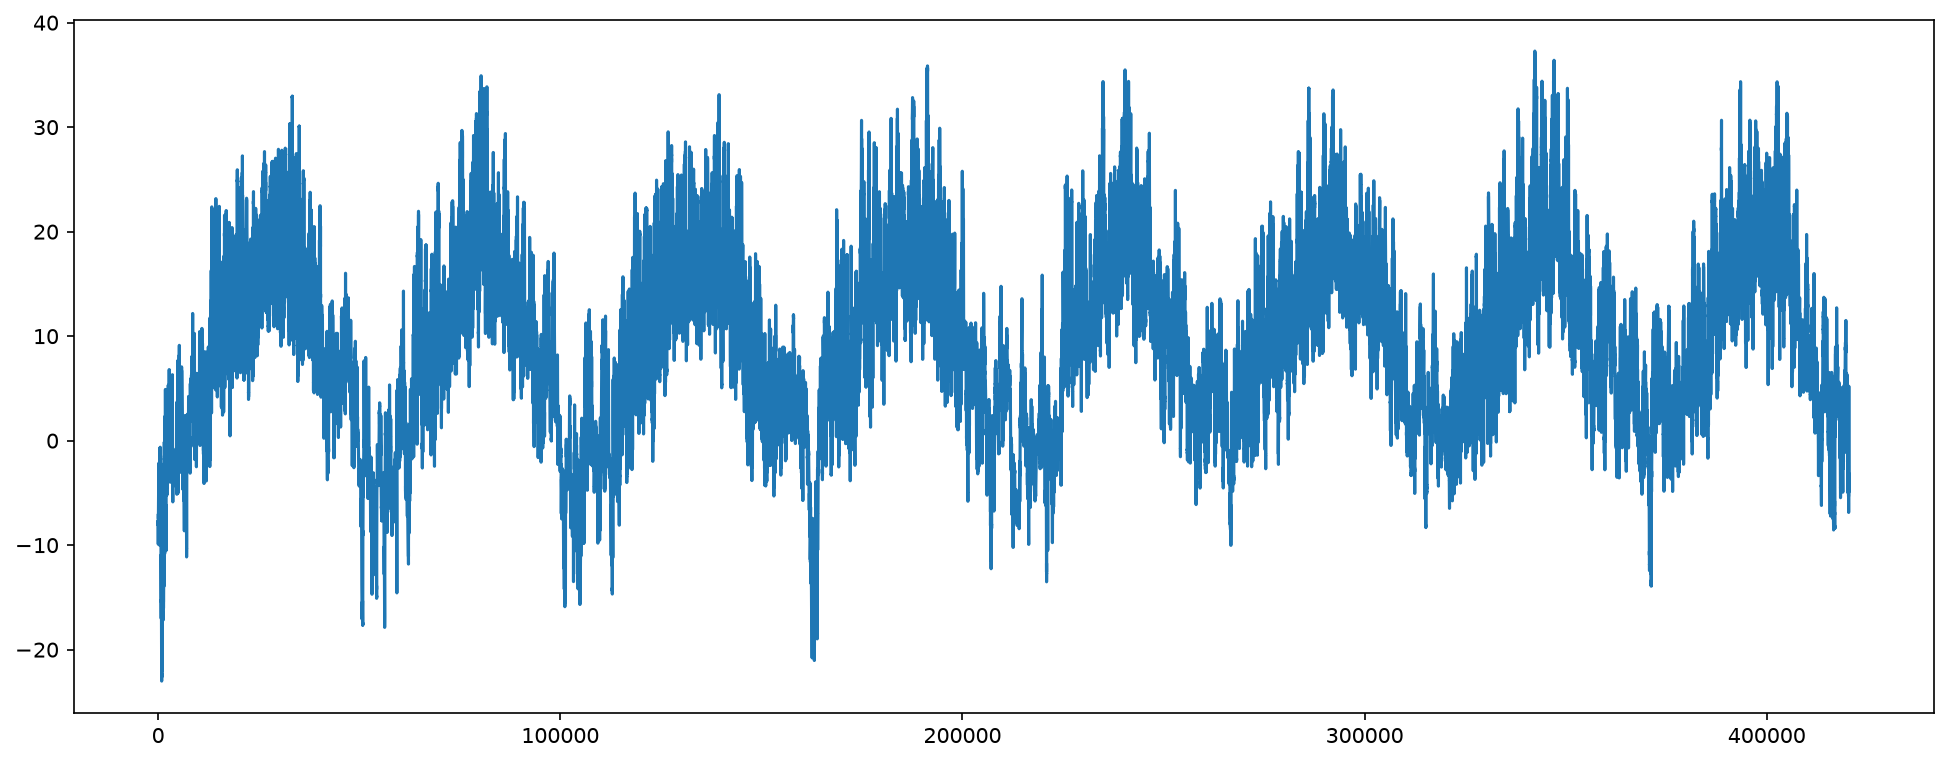

In [9]:
fig = plt.figure(dpi = 150, figsize = (16,6))
plt.plot(range(len(temperature)), temperature)

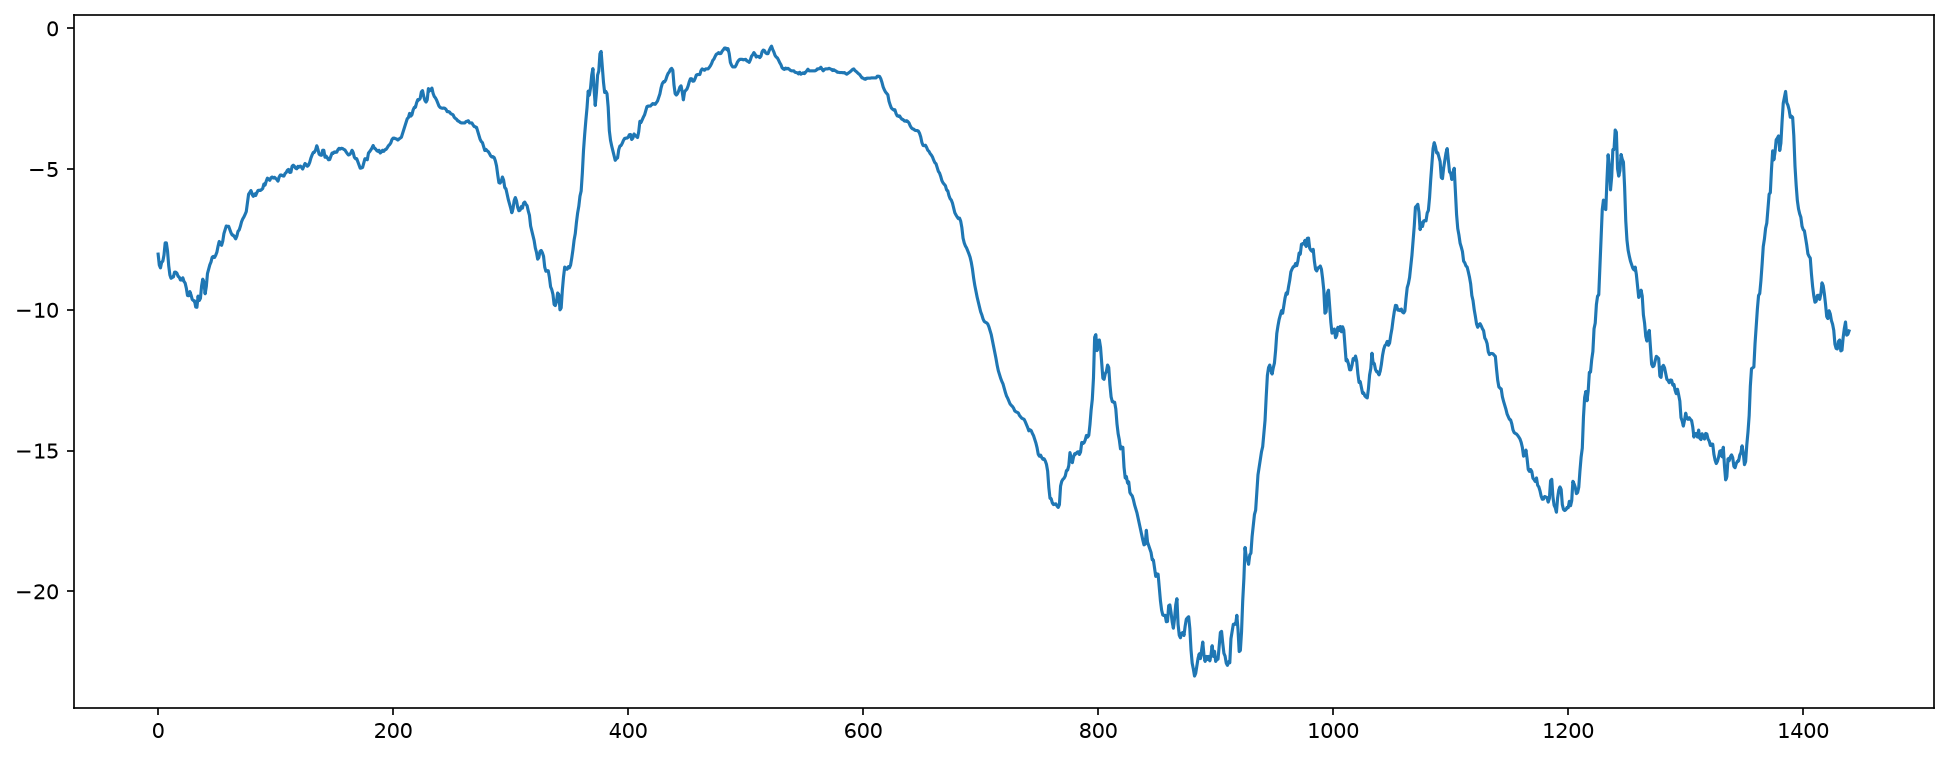

In [10]:
fig = plt.figure(dpi = 150, figsize = (16,6))
plt.plot(range(1440), temperature[:1440])

Разбиваем данные на обучающий, проверочный и тестовый наборы

In [11]:
num_train_samples = int(0.5 * len(raw_data))
num_val_samples = int(0.25 * len(raw_data))
num_test_samples = len(raw_data) - num_train_samples - num_val_samples
print("Количество измерений в обучающем наборе:", num_train_samples)
print("Количество измерений в проверочном наборе:", num_val_samples)
print("Количество измерений в тестовом наборе:", num_test_samples)

Количество измерений в обучающем наборе: 210225
Количество измерений в проверочном наборе: 105112
Количество измерений в тестовом наборе: 105114


Нормализуем данные

In [12]:
mean = raw_data[:num_train_samples].mean(axis=0)
raw_data -= mean
std = raw_data[:num_train_samples].std(axis=0)
raw_data /= std

## Визуализация данных

In [13]:
feature_names = header[1:]
print("Признаки:", feature_names)

Признаки: ['"p (mbar)"', '"T (degC)"', '"Tpot (K)"', '"Tdew (degC)"', '"rh (%)"', '"VPmax (mbar)"', '"VPact (mbar)"', '"VPdef (mbar)"', '"sh (g/kg)"', '"H2OC (mmol/mol)"', '"rho (g/m**3)"', '"wv (m/s)"', '"max. wv (m/s)"', '"wd (deg)"']


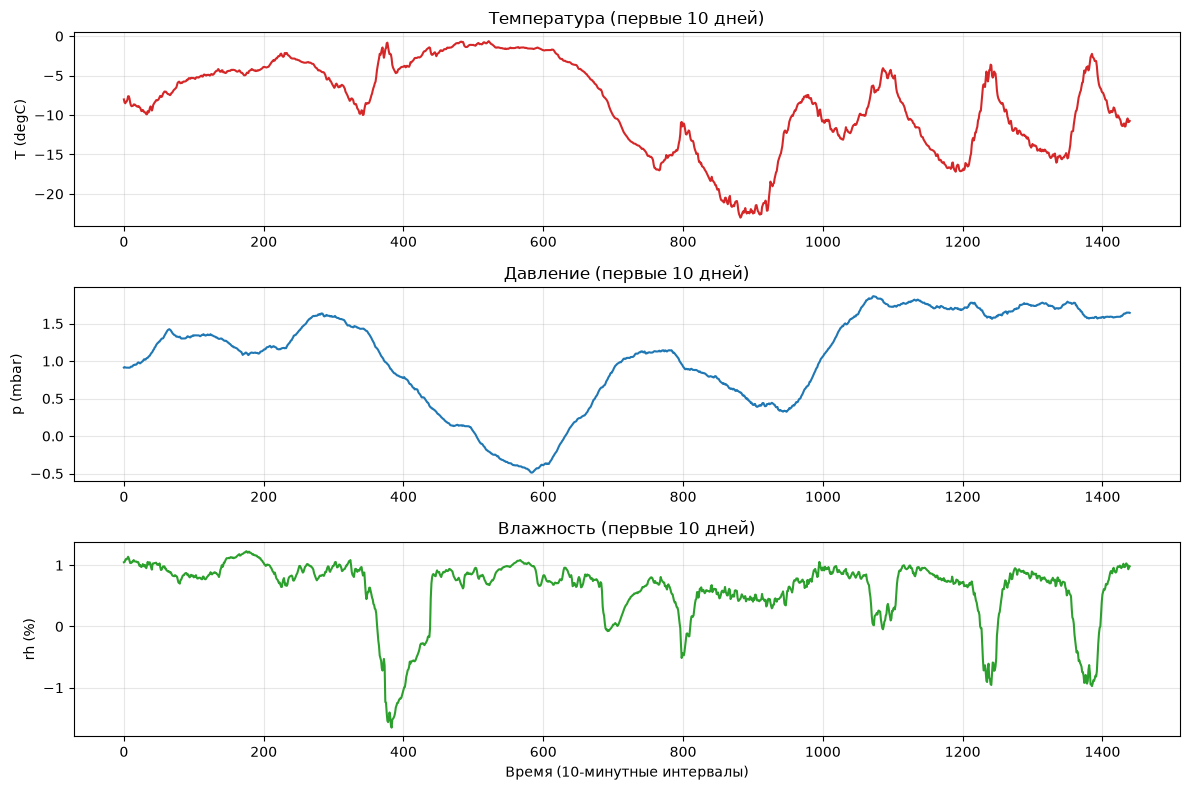

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8))

axes[0].plot(temperature[:1440], color='tab:red')
axes[0].set_title('Температура (первые 10 дней)')
axes[0].set_ylabel('T (degC)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(raw_data[:1440, 0], color='tab:blue')
axes[1].set_title('Давление (первые 10 дней)')
axes[1].set_ylabel('p (mbar)')
axes[1].grid(True, alpha=0.3)

axes[2].plot(raw_data[:1440, 4], color='tab:green')
axes[2].set_title('Влажность (первые 10 дней)')
axes[2].set_ylabel('rh (%)')
axes[2].set_xlabel('Время (10-минутные интервалы)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

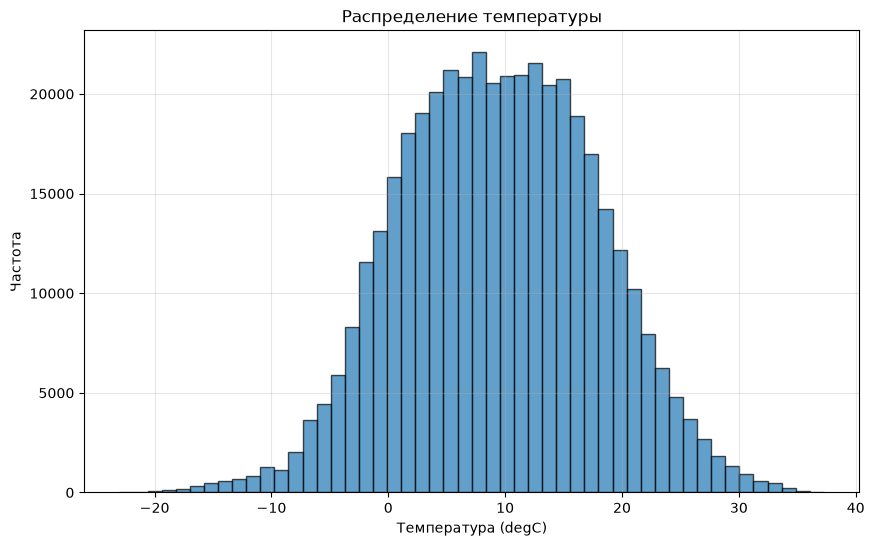

In [15]:
plt.figure(figsize=(10, 6))
plt.hist(temperature, bins=50, color='tab:blue', alpha=0.7, edgecolor='black')
plt.title('Распределение температуры')
plt.xlabel('Температура (degC)')
plt.ylabel('Частота')
plt.grid(True, alpha=0.3)
plt.show()

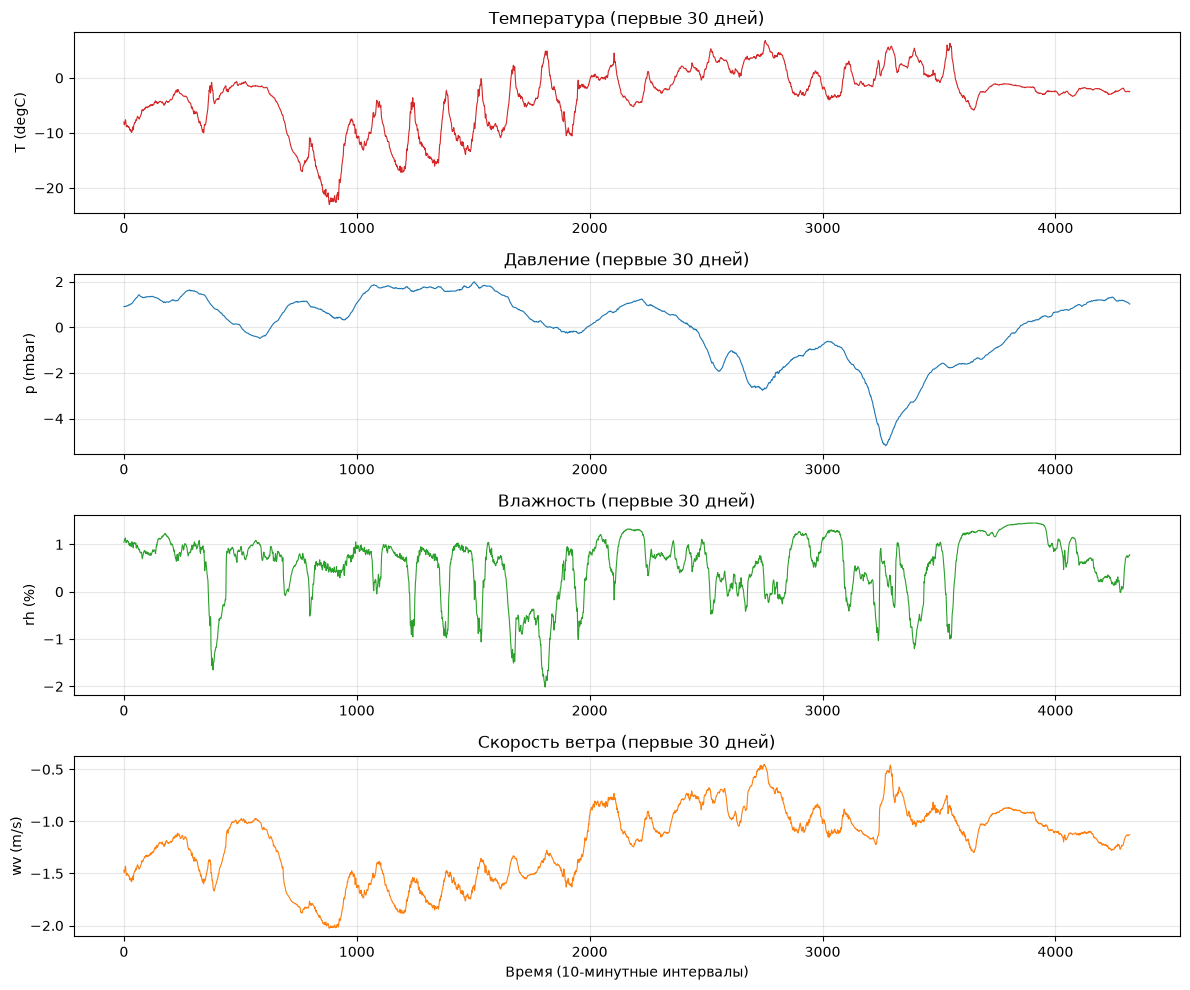

In [16]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10))

days = 30
period = days * 144

axes[0].plot(temperature[:period], color='tab:red', linewidth=0.8)
axes[0].set_title(f'Температура (первые {days} дней)')
axes[0].set_ylabel('T (degC)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(raw_data[:period, 0], color='tab:blue', linewidth=0.8)
axes[1].set_title(f'Давление (первые {days} дней)')
axes[1].set_ylabel('p (mbar)')
axes[1].grid(True, alpha=0.3)

axes[2].plot(raw_data[:period, 4], color='tab:green', linewidth=0.8)
axes[2].set_title(f'Влажность (первые {days} дней)')
axes[2].set_ylabel('rh (%)')
axes[2].grid(True, alpha=0.3)

axes[3].plot(raw_data[:period, 6], color='tab:orange', linewidth=0.8)
axes[3].set_title(f'Скорость ветра (первые {days} дней)')
axes[3].set_ylabel('wv (m/s)')
axes[3].set_xlabel('Время (10-минутные интервалы)')
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

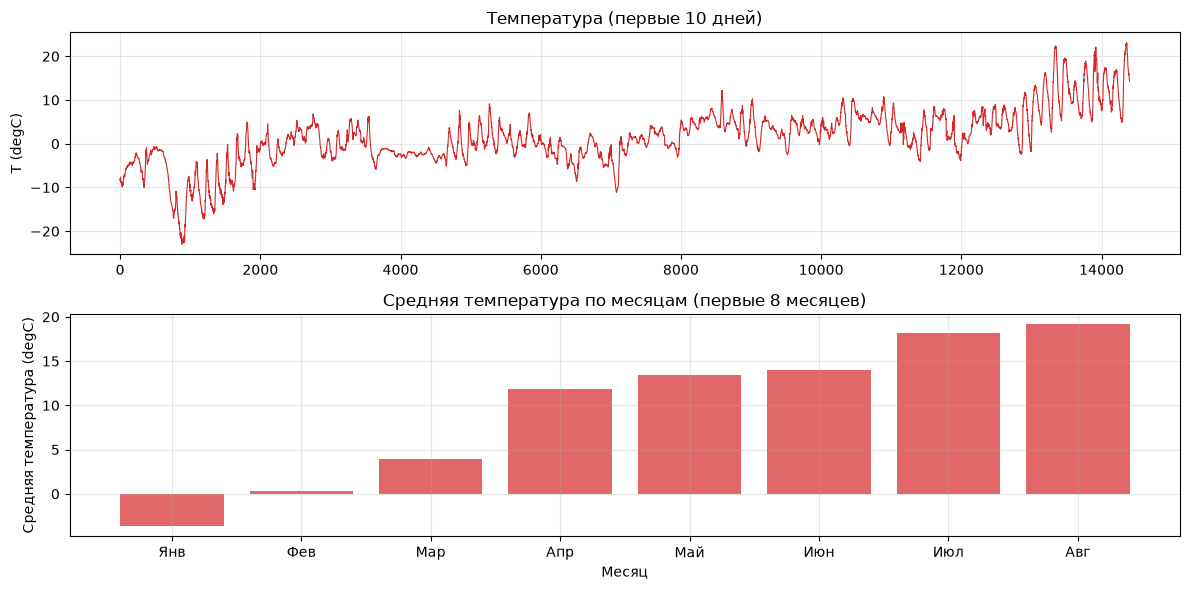

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].plot(temperature[:14400], color='tab:red', linewidth=0.8)
axes[0].set_title('Температура (первые 10 дней)')
axes[0].set_ylabel('T (degC)')
axes[0].grid(True, alpha=0.3)

monthly_means = [np.mean(temperature[i*4320:(i+1)*4320]) for i in range(8)]  # ~30 дней * 144 измерения/день
axes[1].bar(range(8), monthly_means, color='tab:red', alpha=0.7)
axes[1].set_title('Средняя температура по месяцам (первые 8 месяцев)')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('Средняя температура (degC)')
axes[1].set_xticks(range(8))
axes[1].set_xticklabels(['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг'])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

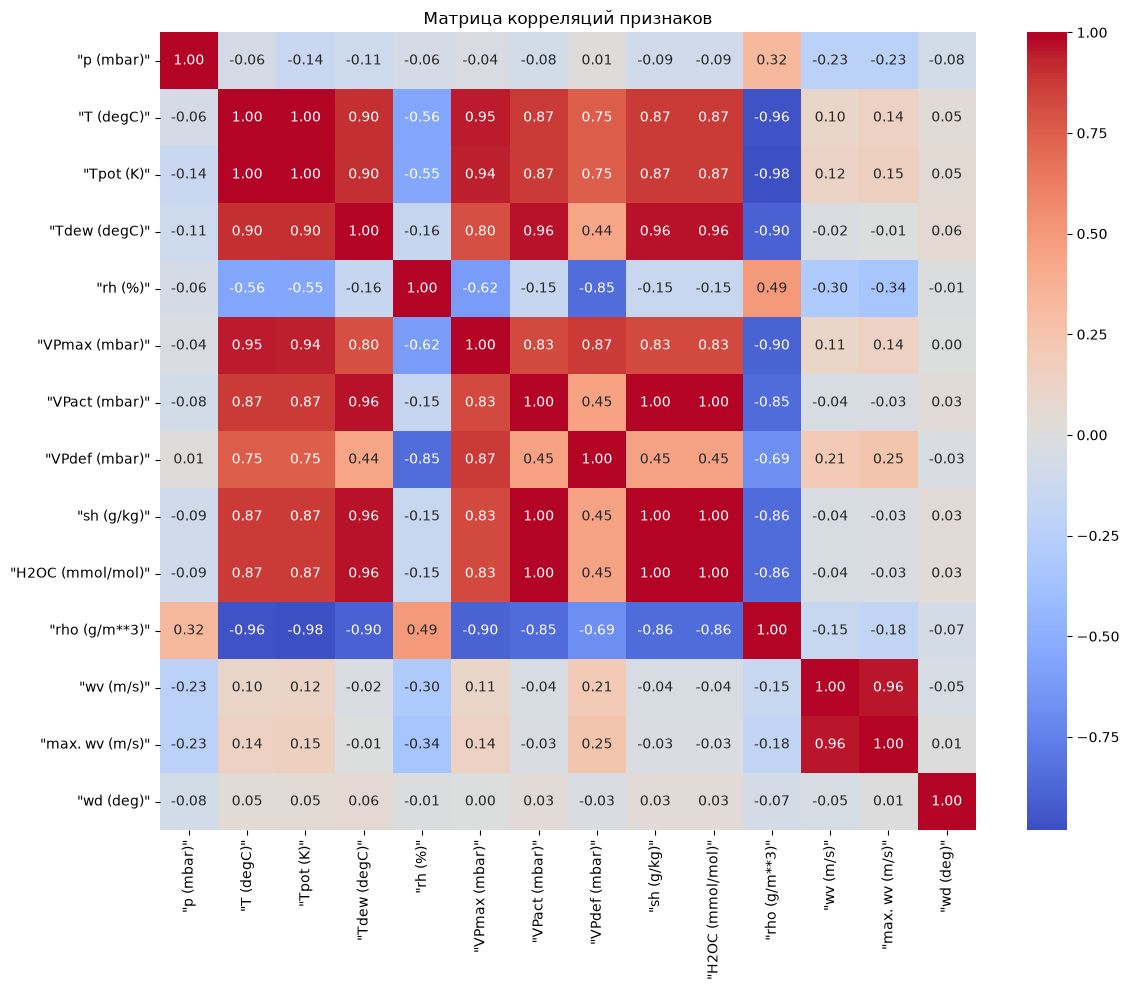

In [18]:
import seaborn as sns

correlation_matrix = np.corrcoef(raw_data[:num_train_samples].T)

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            xticklabels=feature_names, yticklabels=feature_names)
plt.title('Матрица корреляций признаков')
plt.tight_layout()
plt.show()

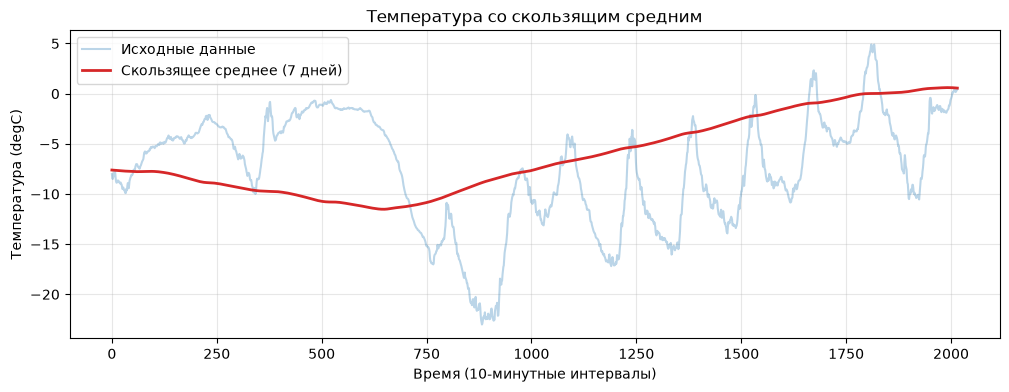

In [19]:
plt.figure(figsize=(12, 4))

window_size = 144 * 7  # 7 дней
rolling_mean = np.convolve(temperature, np.ones(window_size)/window_size, mode='valid')

plt.plot(temperature[:window_size*2], alpha=0.3, label='Исходные данные', color='tab:blue')
plt.plot(rolling_mean[:window_size*2], label=f'Скользящее среднее ({window_size // 144} дней)', 
         color='tab:red', linewidth=2)
plt.title('Температура со скользящим средним')
plt.xlabel('Время (10-минутные интервалы)')
plt.ylabel('Температура (degC)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

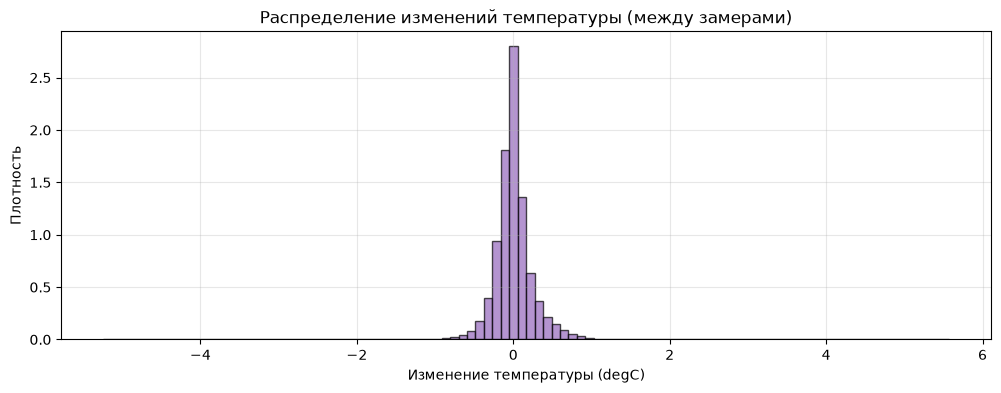

Среднее изменение: 0.0000 degC
Стд. отклонение изменений: 0.2484 degC
Максимальное увеличение: 5.5700 degC
Максимальное уменьшение: -5.2400 degC


In [20]:
plt.figure(figsize=(12, 4))

temp_diff = np.diff(temperature)
plt.hist(temp_diff, bins=100, color='tab:purple', alpha=0.7, edgecolor='black', density=True)
plt.title('Распределение изменений температуры (между замерами)')
plt.xlabel('Изменение температуры (degC)')
plt.ylabel('Плотность')
plt.grid(True, alpha=0.3)
plt.show()

print(f'Среднее изменение: {np.mean(temp_diff):.4f} degC')
print(f'Стд. отклонение изменений: {np.std(temp_diff):.4f} degC')
print(f'Максимальное увеличение: {np.max(temp_diff):.4f} degC')
print(f'Максимальное уменьшение: {np.min(temp_diff):.4f} degC')

## Создаем Dataset для PyTorch

In [21]:
class TimeSeriesDataset(Dataset):
    def __init__(self, data, targets, sampling_rate, sequence_length):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.targets = torch.tensor(targets, dtype=torch.float32)
        self.sampling_rate = sampling_rate
        self.sequence_length = sequence_length
        self.length = (len(data) - sequence_length * sampling_rate) // sampling_rate
        
    def __len__(self):
        return self.length
    
    def __getitem__(self, idx):
        start = idx * self.sampling_rate
        end = start + self.sequence_length * self.sampling_rate
        sequence = self.data[start:end:self.sampling_rate]
        target = self.targets[idx * self.sampling_rate + self.sequence_length * self.sampling_rate]
        return sequence, target

In [22]:
sampling_rate = 6
sequence_length = 120
delay = sampling_rate * (sequence_length + 24 - 1)
batch_size = 256

train_dataset = TimeSeriesDataset(
    raw_data[:num_train_samples],
    temperature,
    sampling_rate,
    sequence_length
)

val_dataset = TimeSeriesDataset(
    raw_data[num_train_samples:num_train_samples + num_val_samples],
    temperature[num_train_samples:num_train_samples + num_val_samples],
    sampling_rate,
    sequence_length
)

test_dataset = TimeSeriesDataset(
    raw_data[num_train_samples + num_val_samples:],
    temperature[num_train_samples + num_val_samples:],
    sampling_rate,
    sequence_length
)

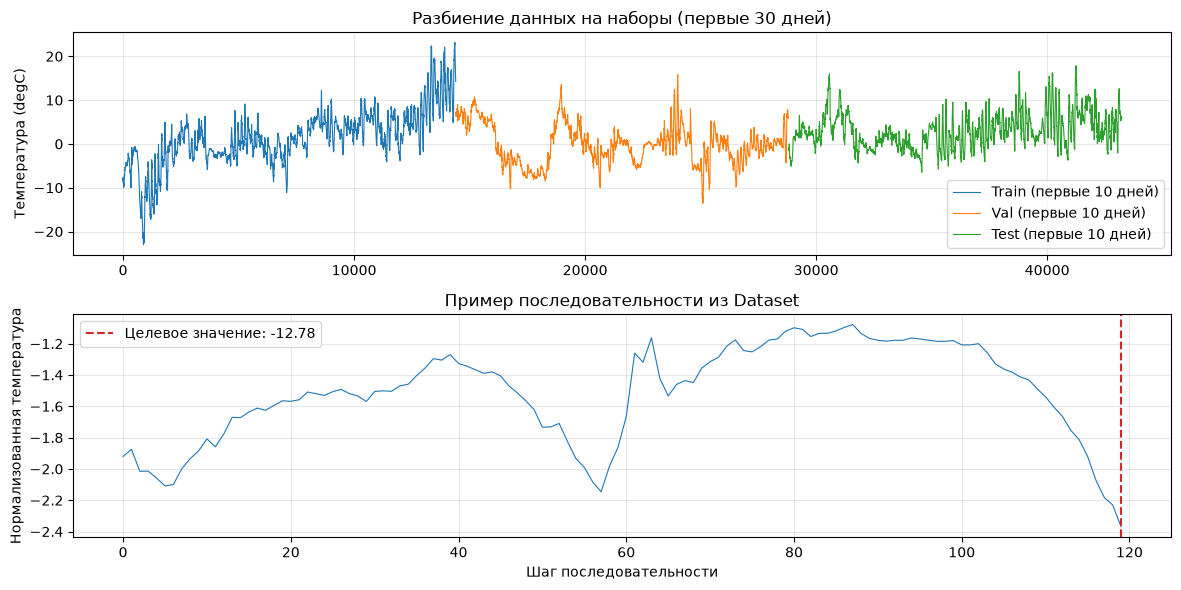

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

train_temperatures = temperature[:num_train_samples]
val_temperatures = temperature[num_train_samples:num_train_samples + num_val_samples]
test_temperatures = temperature[num_train_samples + num_val_samples:]

axes[0].plot(train_temperatures[:14400], color='tab:blue', label='Train (первые 10 дней)', linewidth=0.8)
axes[0].plot(range(14400, 14400 + len(val_temperatures[:14400])), val_temperatures[:14400], color='tab:orange', label='Val (первые 10 дней)', linewidth=0.8)
axes[0].plot(range(14400 + len(val_temperatures[:14400]), 14400 + len(val_temperatures[:14400]) + len(test_temperatures[:14400])), test_temperatures[:14400], color='tab:green', label='Test (первые 10 дней)', linewidth=0.8)
axes[0].set_title('Разбиение данных на наборы (первые 30 дней)')
axes[0].set_ylabel('Температура (degC)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

sample_idx = 0
sample_x, sample_y = train_dataset[sample_idx]
axes[1].plot(sample_x.numpy()[:, 1], color='tab:blue', linewidth=0.8)
axes[1].axvline(x=len(sample_x) - 1, color='tab:red', linestyle='--', label=f'Целевое значение: {sample_y:.2f}')
axes[1].set_title('Пример последовательности из Dataset')
axes[1].set_ylabel('Нормализованная температура')
axes[1].set_xlabel('Шаг последовательности')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

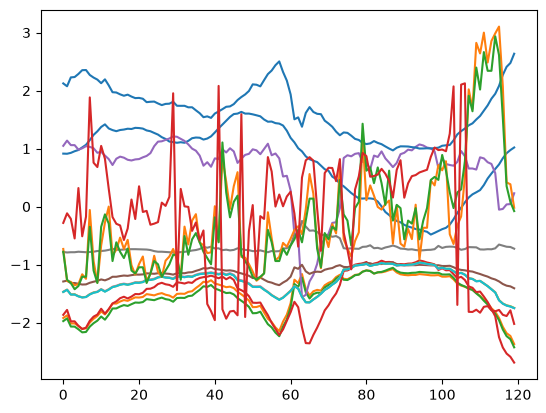

In [24]:
plt.plot(train_dataset[0][0]);

In [25]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

In [26]:
for samples, targets in train_loader:
    print("Размерность обучающей мини-выборки:", samples.shape)
    print("Размерность целевой переменной:", targets.shape)
    break

Размерность обучающей мини-выборки: torch.Size([256, 120, 14])
Размерность целевой переменной: torch.Size([256])


## Создаем базовое решение

Всегда предсказываем последнее значение

In [27]:
def evaluate_naive_method(dataset):
    """Наивный прогноз: температура останется такой же, как в последний момент окна."""
    total_abs_err = 0.0
    samples_seen = 0
    loader = dataset if hasattr(dataset, 'batch_size') else DataLoader(dataset, batch_size=batch_size)
    for samples, targets in loader:
        samples = samples.detach().cpu().numpy() if hasattr(samples, 'detach') else np.asarray(samples)
        targets = targets.detach().cpu().numpy() if hasattr(targets, 'detach') else np.asarray(targets)
        # samples: (B, seq_len, n_features), берём последний шаг по температуре (индекс 1)
        preds = samples[:, -1, 1] * std[1] + mean[1]
        total_abs_err += np.sum(np.abs(preds - targets))
        samples_seen += samples.shape[0]
    return total_abs_err / samples_seen if samples_seen > 0 else float('nan')

print(f"Validation MAE (наивный метод, degC): {evaluate_naive_method(val_dataset):.2f}")
print(f"Test MAE (наивный метод, degC): {evaluate_naive_method(test_dataset):.2f}")

Validation MAE (наивный метод, degC): 0.68


Test MAE (наивный метод, degC): 0.72


## Полносвязная нейронная сеть

In [28]:
class DenseModel(nn.Module):
    def __init__(self, input_dim):
        super(DenseModel, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(input_dim * sequence_length, 16)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(16, 1)
        
    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x.squeeze(-1)

In [29]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [30]:
def train_model(model, train_loader, val_loader, epochs=10, lr=0.001):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    
    history = {'train_mae': [], 'val_mae': []}
    best_val_mae = float('inf')
    best_model_state = None
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0
        train_mae = 0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            output = model(batch_x)
            loss = criterion(output, batch_y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * batch_x.size(0)
            train_mae += torch.sum(torch.abs(output - batch_y)).item()
        
        model.eval()
        val_loss = 0
        val_mae = 0
        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                output = model(batch_x)
                val_loss += criterion(output, batch_y).item() * batch_x.size(0)
                val_mae += torch.sum(torch.abs(output - batch_y)).item()
        
        train_mae /= len(train_loader.dataset)
        val_mae /= len(val_loader.dataset)
        
        history['train_mae'].append(train_mae)
        history['val_mae'].append(val_mae)
        
        print(f"Epoch {epoch+1}/{epochs} - Train MAE: {train_mae:.4f} - Val MAE: {val_mae:.4f}")
        
        if val_mae < best_val_mae:
            best_val_mae = val_mae
            best_model_state = model.state_dict().copy()
    
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    
    return model, history

In [88]:
model_dense = DenseModel(raw_data.shape[-1])
model_dense, history_dense = train_model(model_dense, train_loader, val_loader, epochs=20)

Epoch 1/20 - Train MAE: 4.4714 - Val MAE: 3.1245
Epoch 2/20 - Train MAE: 2.4263 - Val MAE: 1.8763
Epoch 3/20 - Train MAE: 1.6125 - Val MAE: 1.3954
Epoch 4/20 - Train MAE: 1.2962 - Val MAE: 1.2174
Epoch 5/20 - Train MAE: 1.1424 - Val MAE: 1.1241
Epoch 6/20 - Train MAE: 1.0615 - Val MAE: 1.0474
Epoch 7/20 - Train MAE: 0.9991 - Val MAE: 1.0244
Epoch 8/20 - Train MAE: 0.9575 - Val MAE: 0.9649
Epoch 9/20 - Train MAE: 0.9209 - Val MAE: 0.9559
Epoch 10/20 - Train MAE: 0.8966 - Val MAE: 0.9861
Epoch 11/20 - Train MAE: 0.8807 - Val MAE: 0.9078
Epoch 12/20 - Train MAE: 0.8497 - Val MAE: 0.9161
Epoch 13/20 - Train MAE: 0.8251 - Val MAE: 0.8908
Epoch 14/20 - Train MAE: 0.8156 - Val MAE: 0.9232
Epoch 15/20 - Train MAE: 0.7983 - Val MAE: 0.8800
Epoch 16/20 - Train MAE: 0.7949 - Val MAE: 0.8833
Epoch 17/20 - Train MAE: 0.7753 - Val MAE: 0.9005
Epoch 18/20 - Train MAE: 0.7759 - Val MAE: 0.8669
Epoch 19/20 - Train MAE: 0.7663 - Val MAE: 0.9161
Epoch 20/20 - Train MAE: 0.7553 - Val MAE: 0.9152


Epoch 2/10 - Train MAE: 2.2324 - Val MAE: 1.6519


Epoch 3/10 - Train MAE: 1.4635 - Val MAE: 1.2867


Epoch 4/10 - Train MAE: 1.2152 - Val MAE: 1.1509


Epoch 5/10 - Train MAE: 1.0872 - Val MAE: 1.1153


Epoch 6/10 - Train MAE: 1.0031 - Val MAE: 1.0295


Epoch 7/10 - Train MAE: 0.9435 - Val MAE: 0.9844


Epoch 8/10 - Train MAE: 0.9061 - Val MAE: 0.9637


Epoch 9/10 - Train MAE: 0.8697 - Val MAE: 0.9349


Epoch 10/10 - Train MAE: 0.8446 - Val MAE: 0.9313


In [89]:
def evaluate_model(model, test_loader):
    model.eval()
    total_mae = 0
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            output = model(batch_x)
            total_mae += torch.sum(torch.abs(output - batch_y)).item()
    return total_mae / len(test_loader.dataset)

print(f"Test MAE: {evaluate_model(model_dense, test_loader):.2f}")

Test MAE: 0.92


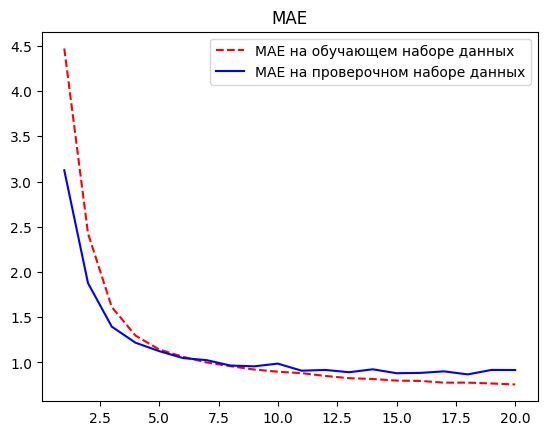

In [90]:
loss = history_dense['train_mae']
val_loss = history_dense['val_mae']
epochs = range(1, len(loss) + 1)
plt.figure()
plt.plot(epochs, loss, "r--", label="MAE на обучающем наборе данных")
plt.plot(epochs, val_loss, "b", label="MAE на проверочном наборе данных")
plt.title("MAE")
plt.legend()
plt.show()

## Одномерная сверточная нейронная сеть

In [91]:
class Conv1DModel(nn.Module):
    def __init__(self, input_dim):
        super(Conv1DModel, self).__init__()
        self.conv1 = nn.Conv1d(input_dim, 8, kernel_size=24)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(8, 8, kernel_size=12)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(2)
        self.conv3 = nn.Conv1d(8, 8, kernel_size=6)
        self.relu3 = nn.ReLU()
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(8, 1)
        
    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.relu3(self.conv3(x))
        x = self.global_pool(x).squeeze(-1)
        x = self.fc(x).squeeze(-1)
        return x

In [92]:
model_conv = Conv1DModel(raw_data.shape[-1])
model_conv, history_conv = train_model(model_conv, train_loader, val_loader, epochs=20)

Epoch 1/20 - Train MAE: 5.5779 - Val MAE: 3.4131
Epoch 2/20 - Train MAE: 3.7542 - Val MAE: 3.2164
Epoch 3/20 - Train MAE: 3.6240 - Val MAE: 3.1188
Epoch 4/20 - Train MAE: 3.4958 - Val MAE: 2.9872
Epoch 5/20 - Train MAE: 3.2958 - Val MAE: 2.7999
Epoch 6/20 - Train MAE: 3.0052 - Val MAE: 2.5798
Epoch 7/20 - Train MAE: 2.8267 - Val MAE: 2.5302
Epoch 8/20 - Train MAE: 2.7302 - Val MAE: 2.4636
Epoch 9/20 - Train MAE: 2.6260 - Val MAE: 2.4516
Epoch 10/20 - Train MAE: 2.5384 - Val MAE: 2.4477
Epoch 11/20 - Train MAE: 2.4872 - Val MAE: 2.4628
Epoch 12/20 - Train MAE: 2.4439 - Val MAE: 2.4286
Epoch 13/20 - Train MAE: 2.4327 - Val MAE: 2.4762
Epoch 14/20 - Train MAE: 2.3678 - Val MAE: 2.3881
Epoch 15/20 - Train MAE: 2.3434 - Val MAE: 2.4039
Epoch 16/20 - Train MAE: 2.2989 - Val MAE: 2.3327
Epoch 17/20 - Train MAE: 2.2809 - Val MAE: 2.3405
Epoch 18/20 - Train MAE: 2.2661 - Val MAE: 2.3444
Epoch 19/20 - Train MAE: 2.2333 - Val MAE: 2.3239
Epoch 20/20 - Train MAE: 2.2154 - Val MAE: 2.3585


Epoch 2/10 - Train MAE: 3.7124 - Val MAE: 3.1916


Epoch 3/10 - Train MAE: 3.4980 - Val MAE: 2.9291


Epoch 4/10 - Train MAE: 3.2200 - Val MAE: 2.7064


Epoch 5/10 - Train MAE: 2.8475 - Val MAE: 2.5960


Epoch 6/10 - Train MAE: 2.6729 - Val MAE: 2.5541


Epoch 7/10 - Train MAE: 2.6297 - Val MAE: 2.5458


Epoch 8/10 - Train MAE: 2.5966 - Val MAE: 2.4994


Epoch 9/10 - Train MAE: 2.5706 - Val MAE: 2.4751


Epoch 10/10 - Train MAE: 2.5408 - Val MAE: 2.4555


In [93]:
print(f"MAE на тестовом наборе данных: {evaluate_model(model_conv, test_loader):.2f}")

MAE на тестовом наборе данных: 2.39


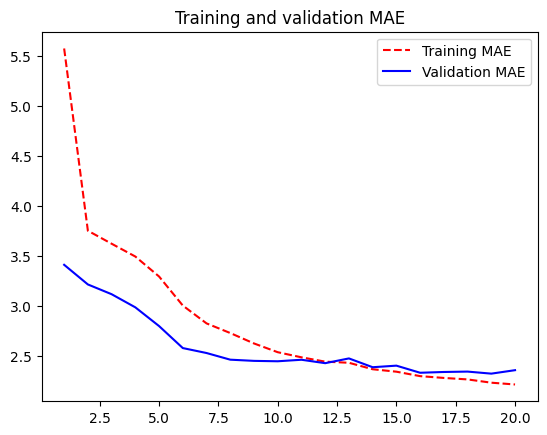

In [94]:
loss = history_conv['train_mae']
val_loss = history_conv['val_mae']
epochs = range(1, len(loss) + 1)
plt.figure()
plt.plot(epochs, loss, "r--", label="Training MAE")
plt.plot(epochs, val_loss, "b", label="Validation MAE")
plt.title("Training and validation MAE")
plt.legend()
plt.show()

## Сеть LSTM

In [38]:
class LSTMModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=16):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        out = self.fc(lstm_out[:, -1, :])
        return out.squeeze(-1)

In [95]:
model_lstm = LSTMModel(raw_data.shape[-1])
model_lstm, history_lstm = train_model(model_lstm, train_loader, val_loader, epochs=20)

Epoch 1/20 - Train MAE: 9.0906 - Val MAE: 7.3577
Epoch 2/20 - Train MAE: 6.3761 - Val MAE: 5.6596
Epoch 3/20 - Train MAE: 5.0798 - Val MAE: 4.4864
Epoch 4/20 - Train MAE: 4.0876 - Val MAE: 3.5902
Epoch 5/20 - Train MAE: 3.3319 - Val MAE: 2.8994
Epoch 6/20 - Train MAE: 2.7556 - Val MAE: 2.3885
Epoch 7/20 - Train MAE: 2.3152 - Val MAE: 1.9934
Epoch 8/20 - Train MAE: 1.9678 - Val MAE: 1.7007
Epoch 9/20 - Train MAE: 1.7029 - Val MAE: 1.4924
Epoch 10/20 - Train MAE: 1.4996 - Val MAE: 1.3214
Epoch 11/20 - Train MAE: 1.3400 - Val MAE: 1.1812
Epoch 12/20 - Train MAE: 1.2116 - Val MAE: 1.0839
Epoch 13/20 - Train MAE: 1.1111 - Val MAE: 0.9919
Epoch 14/20 - Train MAE: 1.0326 - Val MAE: 0.9258
Epoch 15/20 - Train MAE: 0.9671 - Val MAE: 0.8579
Epoch 16/20 - Train MAE: 0.9094 - Val MAE: 0.8210
Epoch 17/20 - Train MAE: 0.8630 - Val MAE: 0.7860
Epoch 18/20 - Train MAE: 0.8222 - Val MAE: 0.7457
Epoch 19/20 - Train MAE: 0.7883 - Val MAE: 0.7109
Epoch 20/20 - Train MAE: 0.7610 - Val MAE: 0.6895


Epoch 2/10 - Train MAE: 6.7909 - Val MAE: 6.0892


Epoch 3/10 - Train MAE: 5.3431 - Val MAE: 4.6531


Epoch 4/10 - Train MAE: 4.1604 - Val MAE: 3.6561


Epoch 5/10 - Train MAE: 3.3544 - Val MAE: 2.9500


Epoch 6/10 - Train MAE: 2.7668 - Val MAE: 2.4242


Epoch 7/10 - Train MAE: 2.3239 - Val MAE: 2.0328


Epoch 8/10 - Train MAE: 1.9916 - Val MAE: 1.7400


Epoch 9/10 - Train MAE: 1.7333 - Val MAE: 1.5214


Epoch 10/10 - Train MAE: 1.5373 - Val MAE: 1.3421


In [96]:
print(f"MAE на тестовом наборе данных: {evaluate_model(model_lstm, test_loader):.2f}")

MAE на тестовом наборе данных: 0.80


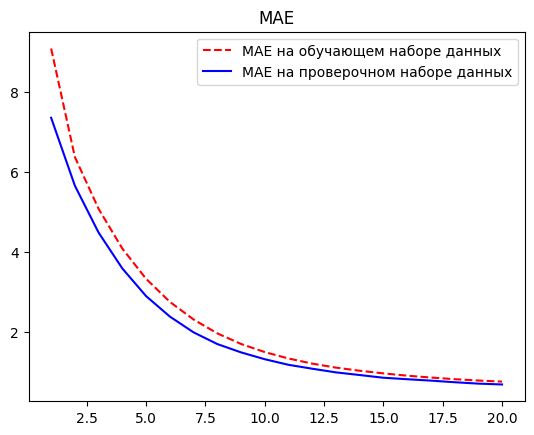

In [97]:
loss = history_lstm['train_mae']
val_loss = history_lstm['val_mae']
epochs = range(1, len(loss) + 1)
plt.figure()
plt.plot(epochs, loss, "r--", label="MAE на обучающем наборе данных")
plt.plot(epochs, val_loss, "b", label="MAE на проверочном наборе данных")
plt.title("MAE")
plt.legend()
plt.show()

Используем Dropout для снижения переобучения

In [98]:
class LSTMWithDropout(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, dropout=0.25):
        super(LSTMWithDropout, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True, dropout=dropout)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        out = self.dropout(lstm_out[:, -1, :])
        out = self.fc(out)
        return out.squeeze(-1)

In [99]:
model_lstm_dropout = LSTMWithDropout(raw_data.shape[-1])
model_lstm_dropout, history_lstm_dropout = train_model(model_lstm_dropout, train_loader, val_loader, epochs=20)

Epoch 1/20 - Train MAE: 7.8630 - Val MAE: 5.6481
Epoch 2/20 - Train MAE: 4.7605 - Val MAE: 3.6429
Epoch 3/20 - Train MAE: 3.5408 - Val MAE: 2.5433
Epoch 4/20 - Train MAE: 2.8799 - Val MAE: 1.9398
Epoch 5/20 - Train MAE: 2.4988 - Val MAE: 1.5549
Epoch 6/20 - Train MAE: 2.2751 - Val MAE: 1.2772
Epoch 7/20 - Train MAE: 2.1350 - Val MAE: 1.1229
Epoch 8/20 - Train MAE: 2.0273 - Val MAE: 1.0346
Epoch 9/20 - Train MAE: 1.9174 - Val MAE: 0.9409
Epoch 10/20 - Train MAE: 1.8520 - Val MAE: 0.8593
Epoch 11/20 - Train MAE: 1.7952 - Val MAE: 0.8255
Epoch 12/20 - Train MAE: 1.7721 - Val MAE: 0.7723
Epoch 13/20 - Train MAE: 1.7328 - Val MAE: 0.7633
Epoch 14/20 - Train MAE: 1.7143 - Val MAE: 0.7440
Epoch 15/20 - Train MAE: 1.6793 - Val MAE: 0.7311
Epoch 16/20 - Train MAE: 1.6755 - Val MAE: 0.7154
Epoch 17/20 - Train MAE: 1.6426 - Val MAE: 0.6747
Epoch 18/20 - Train MAE: 1.6324 - Val MAE: 0.6507
Epoch 19/20 - Train MAE: 1.6315 - Val MAE: 0.7044
Epoch 20/20 - Train MAE: 1.6021 - Val MAE: 0.6362


Epoch 2/20 - Train MAE: 4.5724 - Val MAE: 3.4598


Epoch 3/20 - Train MAE: 3.4204 - Val MAE: 2.4324


Epoch 4/20 - Train MAE: 2.8116 - Val MAE: 1.8425


Epoch 5/20 - Train MAE: 2.4459 - Val MAE: 1.4750


...

Epoch 16/20 - Train MAE: 1.6887 - Val MAE: 0.7279


Epoch 17/20 - Train MAE: 1.6645 - Val MAE: 0.6592


Epoch 18/20 - Train MAE: 1.6451 - Val MAE: 0.7247


Epoch 19/20 - Train MAE: 1.6474 - Val MAE: 0.6523


Epoch 20/20 - Train MAE: 1.6373 - Val MAE: 0.6526


In [100]:
print(f"MAE на тестовом наборе данных: {evaluate_model(model_lstm_dropout, test_loader):.2f}")

MAE на тестовом наборе данных: 0.70


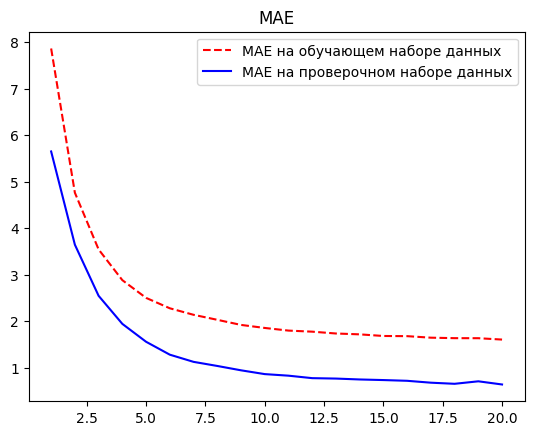

In [101]:
loss = history_lstm_dropout['train_mae']
val_loss = history_lstm_dropout['val_mae']
epochs = range(1, len(loss) + 1)
plt.figure()
plt.plot(epochs, loss, "r--", label="MAE на обучающем наборе данных")
plt.plot(epochs, val_loss, "b", label="MAE на проверочном наборе данных")
plt.title("MAE")
plt.legend()
plt.show()

In [102]:
t=next(iter(test_loader))
t[0].shape

torch.Size([256, 120, 14])

In [103]:
# s = test_loader.dataset[0]
# print(s[0].size(), s[1].size())
# model_lstm_dropout(t[0])

## Несколько рекуррентных слоев

In [104]:
class StackedGRU(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, dropout=0.5):
        super(StackedGRU, self).__init__()
        self.gru1 = nn.GRU(input_dim, hidden_dim, batch_first=True, dropout=dropout)
        self.gru2 = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        out, _ = self.gru1(x)
        out, _ = self.gru2(out)
        out = self.dropout(out[:, -1, :])
        out = self.fc(out)
        return out.squeeze(-1)

In [105]:
model_stacked_gru = StackedGRU(raw_data.shape[-1])
model_stacked_gru, history_stacked_gru = train_model(model_stacked_gru, train_loader, val_loader, epochs=20)

Epoch 1/20 - Train MAE: 7.3960 - Val MAE: 5.3794
Epoch 2/20 - Train MAE: 4.3251 - Val MAE: 3.3368
Epoch 3/20 - Train MAE: 3.1339 - Val MAE: 2.3174
Epoch 4/20 - Train MAE: 2.5293 - Val MAE: 1.7785
Epoch 5/20 - Train MAE: 2.1842 - Val MAE: 1.3799
Epoch 6/20 - Train MAE: 1.9534 - Val MAE: 1.1714
Epoch 7/20 - Train MAE: 1.8433 - Val MAE: 1.0324
Epoch 8/20 - Train MAE: 1.7506 - Val MAE: 0.9680
Epoch 9/20 - Train MAE: 1.6957 - Val MAE: 0.8478
Epoch 10/20 - Train MAE: 1.6526 - Val MAE: 0.8364
Epoch 11/20 - Train MAE: 1.6451 - Val MAE: 0.7496
Epoch 12/20 - Train MAE: 1.6142 - Val MAE: 0.7070
Epoch 13/20 - Train MAE: 1.6141 - Val MAE: 0.6909
Epoch 14/20 - Train MAE: 1.5903 - Val MAE: 0.7015
Epoch 15/20 - Train MAE: 1.5861 - Val MAE: 0.6603
Epoch 16/20 - Train MAE: 1.5754 - Val MAE: 0.6492
Epoch 17/20 - Train MAE: 1.5530 - Val MAE: 0.6772
Epoch 18/20 - Train MAE: 1.5687 - Val MAE: 0.7065
Epoch 19/20 - Train MAE: 1.5459 - Val MAE: 0.6409
Epoch 20/20 - Train MAE: 1.5526 - Val MAE: 0.6986


Epoch 2/20 - Train MAE: 4.3664 - Val MAE: 3.4000


Epoch 3/20 - Train MAE: 3.1253 - Val MAE: 2.3246


Epoch 4/20 - Train MAE: 2.5198 - Val MAE: 1.7370


Epoch 5/20 - Train MAE: 2.1664 - Val MAE: 1.3863


...

Epoch 16/20 - Train MAE: 1.5777 - Val MAE: 0.6923


Epoch 17/20 - Train MAE: 1.5785 - Val MAE: 0.6926


Epoch 18/20 - Train MAE: 1.5739 - Val MAE: 0.9065


Epoch 19/20 - Train MAE: 1.5491 - Val MAE: 0.6478


Epoch 20/20 - Train MAE: 1.5418 - Val MAE: 0.5695


In [106]:
print(f"MAE на тестовом наборе данных: {evaluate_model(model_stacked_gru, test_loader):.2f}")

MAE на тестовом наборе данных: 0.77


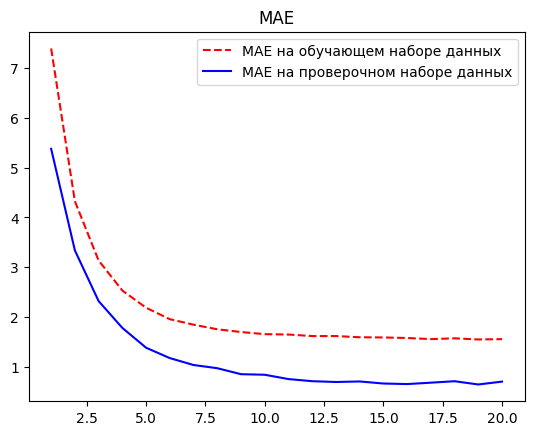

In [107]:
loss = history_stacked_gru['train_mae']
val_loss = history_stacked_gru['val_mae']
epochs = range(1, len(loss) + 1)
plt.figure()
plt.plot(epochs, loss, "r--", label="MAE на обучающем наборе данных")
plt.plot(epochs, val_loss, "b", label="MAE на проверочном наборе данных")
plt.title("MAE")
plt.legend()
plt.show()

## Используем двунаправленную рекуррентную сеть

In [108]:
class BidirectionalLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=16):
        super(BidirectionalLSTM, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, 1)
        
    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        out = self.fc(lstm_out[:, -1, :])
        return out.squeeze(-1)

In [109]:
model_bilstm = BidirectionalLSTM(raw_data.shape[-1])
model_bilstm, history_bilstm = train_model(model_bilstm, train_loader, val_loader, epochs=20)

Epoch 1/20 - Train MAE: 9.1207 - Val MAE: 7.0974
Epoch 2/20 - Train MAE: 5.5754 - Val MAE: 4.2024
Epoch 3/20 - Train MAE: 3.5160 - Val MAE: 2.6120
Epoch 4/20 - Train MAE: 2.5196 - Val MAE: 2.0361
Epoch 5/20 - Train MAE: 2.0610 - Val MAE: 1.7081
Epoch 6/20 - Train MAE: 1.7512 - Val MAE: 1.4441
Epoch 7/20 - Train MAE: 1.5363 - Val MAE: 1.2677
Epoch 8/20 - Train MAE: 1.3490 - Val MAE: 1.0994
Epoch 9/20 - Train MAE: 1.1892 - Val MAE: 0.9822
Epoch 10/20 - Train MAE: 1.0729 - Val MAE: 0.9010
Epoch 11/20 - Train MAE: 0.9911 - Val MAE: 0.8342
Epoch 12/20 - Train MAE: 0.9253 - Val MAE: 0.7810
Epoch 13/20 - Train MAE: 0.8715 - Val MAE: 0.7339
Epoch 14/20 - Train MAE: 0.8235 - Val MAE: 0.7012
Epoch 15/20 - Train MAE: 0.7795 - Val MAE: 0.6693
Epoch 16/20 - Train MAE: 0.7432 - Val MAE: 0.6503
Epoch 17/20 - Train MAE: 0.7146 - Val MAE: 0.6346
Epoch 18/20 - Train MAE: 0.6865 - Val MAE: 0.6054
Epoch 19/20 - Train MAE: 0.6640 - Val MAE: 0.6005
Epoch 20/20 - Train MAE: 0.6440 - Val MAE: 0.5767


Epoch 2/20 - Train MAE: 5.6661 - Val MAE: 4.2878


Epoch 3/20 - Train MAE: 3.5358 - Val MAE: 2.6296


Epoch 4/20 - Train MAE: 2.4948 - Val MAE: 2.0061


Epoch 5/20 - Train MAE: 2.0309 - Val MAE: 1.6568


...

Epoch 16/20 - Train MAE: 0.7393 - Val MAE: 0.6428


Epoch 17/20 - Train MAE: 0.7091 - Val MAE: 0.6207


Epoch 18/20 - Train MAE: 0.6814 - Val MAE: 0.6047


Epoch 19/20 - Train MAE: 0.6587 - Val MAE: 0.5939


Epoch 20/20 - Train MAE: 0.6402 - Val MAE: 0.5715


In [110]:
print(f"MAE на тестовом наборе данных: {evaluate_model(model_bilstm, test_loader):.2f}")

MAE на тестовом наборе данных: 0.63


## Прогнозирование на несколько шагов вперёд

Одношаговое прогнозирование предсказывает температуру только на следующий момент времени. Часто на практике нужно спрогнозировать погоду **на несколько часов вперёд** (горизонт прогнозирования).

Здесь мы реализуем **авторегрессивное (recursive) прогнозирование** на горизонт `horizon = 24` шага с шагом `sampling_rate=6` (то есть **на 24 часа вперёд**). Схема работы:

1. Берём входное окно из тестового набора (последние 120 отсчётов с шагом 1 час = история 5 суток).
2. Для каждого шага прогноза:
   - Предсказываем температуру на следующий час (один шаг).
   - Сдвигаем окно: убираем самый старый замер, добавляем на место самого нового **прогнозное** значение температуры (и оставляем остальные признаки без изменений — приближение).
3. Повторяем 24 раза, получая прогноз на 24 часа вперёд.
4. Сравниваем полученный прогноз с фактическими значениями температуры через 1..24 часа.

Такой подход позволяет оценить, насколько модель сохраняет точность при увеличении горизонта прогнозирования.

In [111]:
def predict_multistep(model, dataset, index=0, horizon=24):
    """
    Авторегрессивное прогнозирование на horizon шагов вперёд.
    Возвращает (preds_horizon, true_horizon) — прогноз и фактические значения
    температуры в градусах Цельсия для следующих horizon шагов.

    Модели обучены предсказывать температуру уже в градусах Цельсия, поэтому
    выход используется напрямую. При подаче прогноза обратно во входное окно
    значение нормируется по статистикам обучающей выборки.
    """
    model.eval()
    with torch.no_grad():
        sample_x, _ = dataset[index]
        seq_in = sample_x.unsqueeze(0).to(device)
        preds_h = []
        for step in range(horizon):
            out = model(seq_in)
            p_c = float(out.squeeze().item())
            preds_h.append(p_c)
            last = seq_in[:, -1:, :].clone()
            last[0, 0, 1] = (p_c - mean[1]) / std[1]
            seq_in = torch.cat([seq_in[:, 1:, :], last], dim=1)

        base = index * sampling_rate + sequence_length * sampling_rate
        n = len(dataset.targets)
        true_h = [dataset.targets[min(base + step * sampling_rate, n - 1)].item()
                  for step in range(horizon)]
    return np.array(preds_h), np.array(true_h)


horizon = 24
eval_indices = np.linspace(0, len(test_dataset) - 1, 50, dtype=int)
plot_index = int(len(test_dataset) // 2)

models_multistep = [
    ('LSTM + Dropout', model_lstm_dropout),
    ('LSTM', model_lstm),
    ('Conv1D', model_conv),
    ('Dense', model_dense),
    ('Stacked GRU', model_stacked_gru),
    ('Bidirectional LSTM', model_bilstm),
]

res = []
plot_curves = {}
for name, m in models_multistep:
    errs = []
    for idx in eval_indices:
        ph, th = predict_multistep(m, test_dataset, index=int(idx), horizon=horizon)
        errs.append(np.abs(ph - th))
    mae_h = float(np.mean(np.stack(errs)))
    res.append((name, mae_h))
    plot_curves[name] = predict_multistep(m, test_dataset, index=plot_index, horizon=horizon)

for name, mae_h in res:
    print(f'{name:15s} MAE на {horizon} ч вперёд: {mae_h:.2f} degC')

LSTM + Dropout  MAE на 24 ч вперёд: 3.51 degC
LSTM            MAE на 24 ч вперёд: 3.50 degC
Conv1D          MAE на 24 ч вперёд: 2.94 degC
Dense           MAE на 24 ч вперёд: 3.48 degC
Stacked GRU     MAE на 24 ч вперёд: 3.52 degC
Bidirectional LSTM MAE на 24 ч вперёд: 3.48 degC


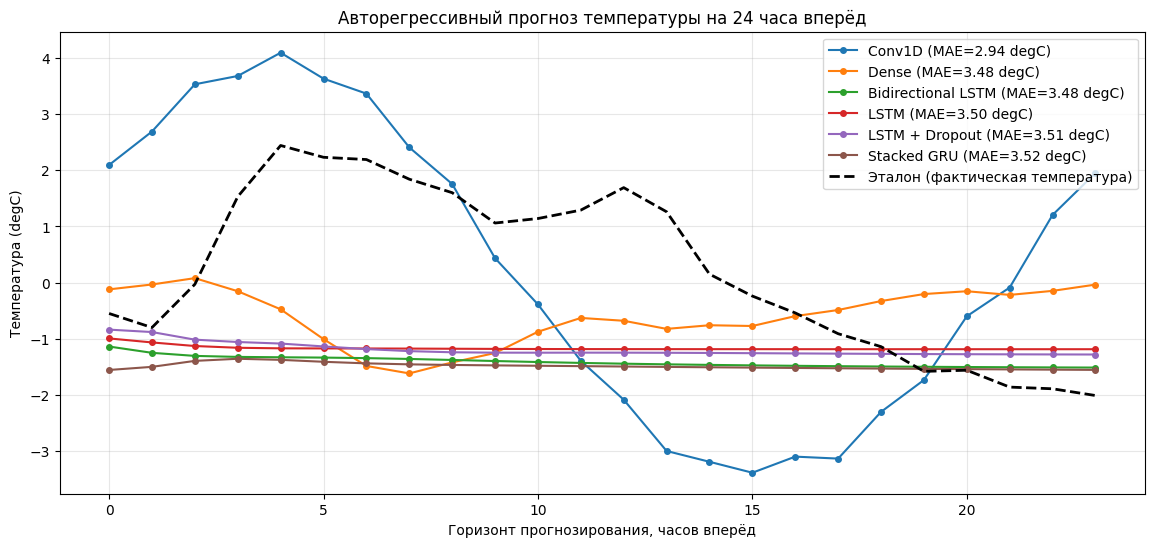

In [112]:
plt.figure(figsize=(14, 6))
hours = np.arange(horizon)
for name, mae_h in sorted(res, key=lambda x: x[1]):
    ph, _ = plot_curves[name]
    plt.plot(hours, ph, marker='o', markersize=4, label=f'{name} (MAE={mae_h:.2f} degC)')
_, true_curve = next(iter(plot_curves.values()))
plt.plot(hours, true_curve, 'k--', linewidth=2, label='Эталон (фактическая температура)')
plt.xlabel('Горизонт прогнозирования, часов вперёд')
plt.ylabel('Температура (degC)')
plt.title('Авторегрессивный прогноз температуры на 24 часа вперёд')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [122]:
print("=" * 70)
print("MAE при прогнозировании на несколько шагов вперёд (усреднение по 50 окнам)")
print("=" * 70)
for name, mae_h in sorted(res, key=lambda x: x[1]):
    print(f"{name:<20} MAE на {horizon}ч: {mae_h:.2f} °C")

MAE при прогнозировании на несколько шагов вперёд (усреднение по 50 окнам)
Conv1D               MAE на 24ч: 2.94 °C
Dense                MAE на 24ч: 3.48 °C
Bidirectional LSTM   MAE на 24ч: 3.48 °C
LSTM                 MAE на 24ч: 3.50 °C
LSTM + Dropout       MAE на 24ч: 3.51 °C
Stacked GRU          MAE на 24ч: 3.52 °C


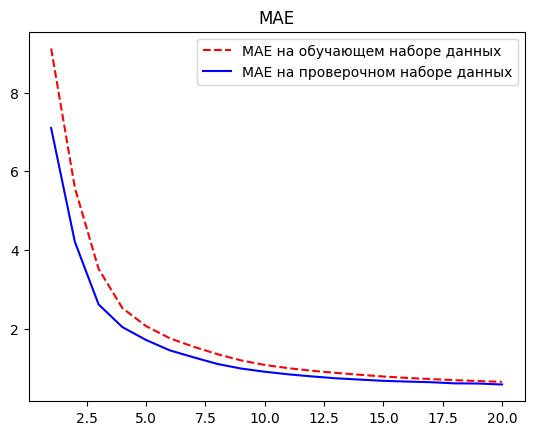

In [123]:
loss = history_bilstm['train_mae']
val_loss = history_bilstm['val_mae']
epochs = range(1, len(loss) + 1)
plt.figure()
plt.plot(epochs, loss, "r--", label="MAE на обучающем наборе данных")
plt.plot(epochs, val_loss, "b", label="MAE на проверочном наборе данных")
plt.title("MAE")
plt.legend()
plt.show()

## Примеры предсказаний

In [124]:
def get_predictions(model, dataset, num_samples=100):
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for i in range(min(num_samples, len(dataset))):
            sample_x, sample_y = dataset[i]
            sample_x = sample_x.unsqueeze(0).to(device)
            pred = model(sample_x).item()
            all_preds.append(pred)
            all_targets.append(sample_y.item() if isinstance(sample_y, torch.Tensor) else sample_y)
    
    return np.array(all_preds), np.array(all_targets)

torch.Size([120, 14])


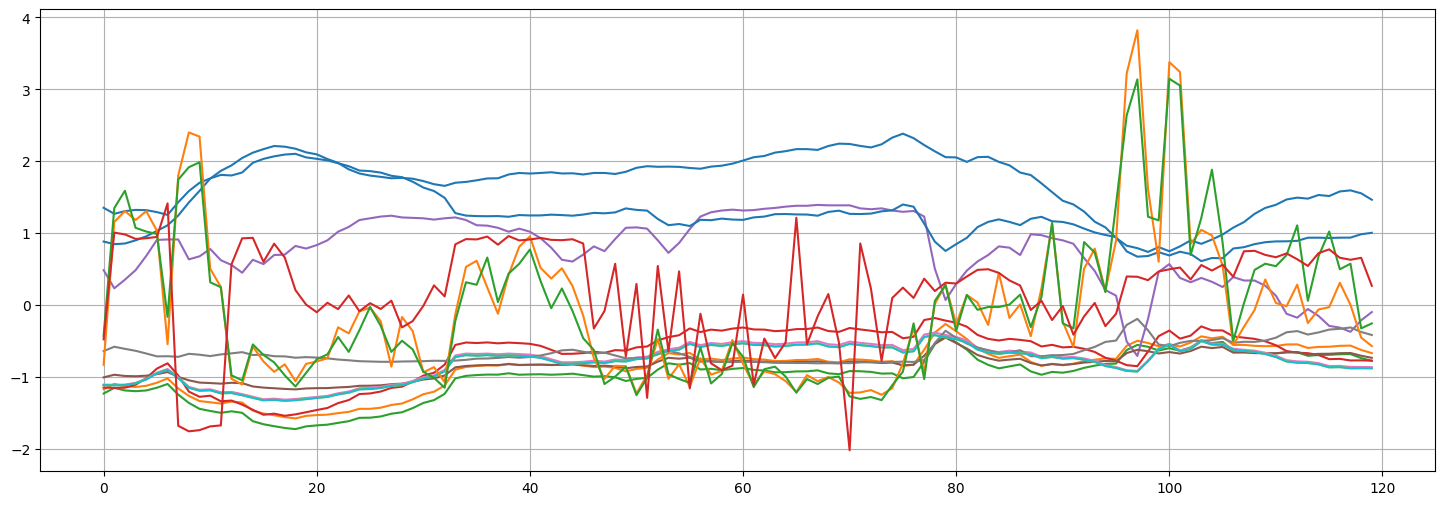

In [125]:
print(test_dataset[0][0].shape)
fig, axes = plt.subplots(1, 1, figsize=(18, 6))
plt.grid()
plt.plot(test_dataset[0][0]);

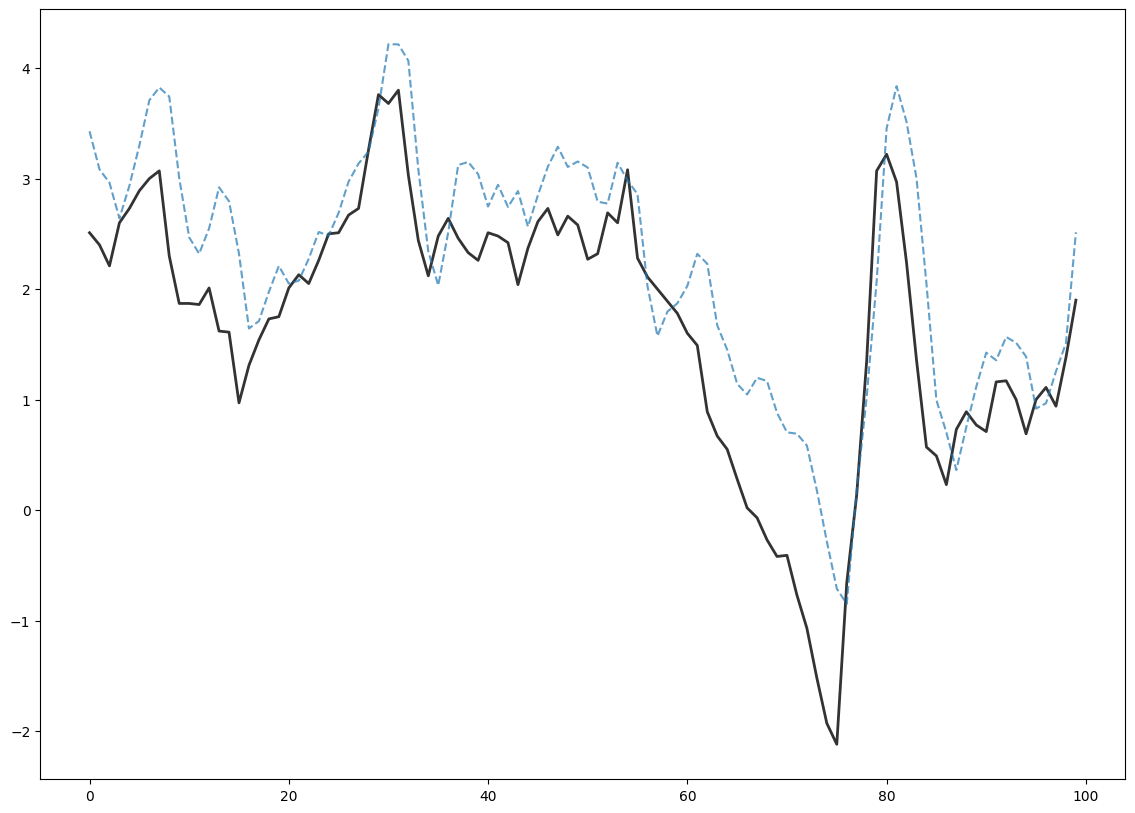

In [126]:
num_examples = 100
fig, axes = plt.subplots(1, 1, figsize=(14, 10))
preds_dense, targets_dense = get_predictions(model_dense, test_dataset, num_examples)
axes.plot(targets_dense, label='Фактические значения', color='black', linewidth=2, alpha=0.8)
axes.plot(preds_dense, label='Dense', linestyle='--', alpha=0.7)

In [127]:

preds_conv, targets_conv = get_predictions(model_conv, test_dataset, num_examples)
preds_lstm, targets_lstm = get_predictions(model_lstm, test_dataset, num_examples)
preds_lstm_dropout, targets_lstm_dropout = get_predictions(model_lstm_dropout, test_dataset, num_examples)
preds_stacked_gru, targets_stacked_gru = get_predictions(model_stacked_gru, test_dataset, num_examples)
preds_bilstm, targets_bilstm = get_predictions(model_bilstm, test_dataset, num_examples)

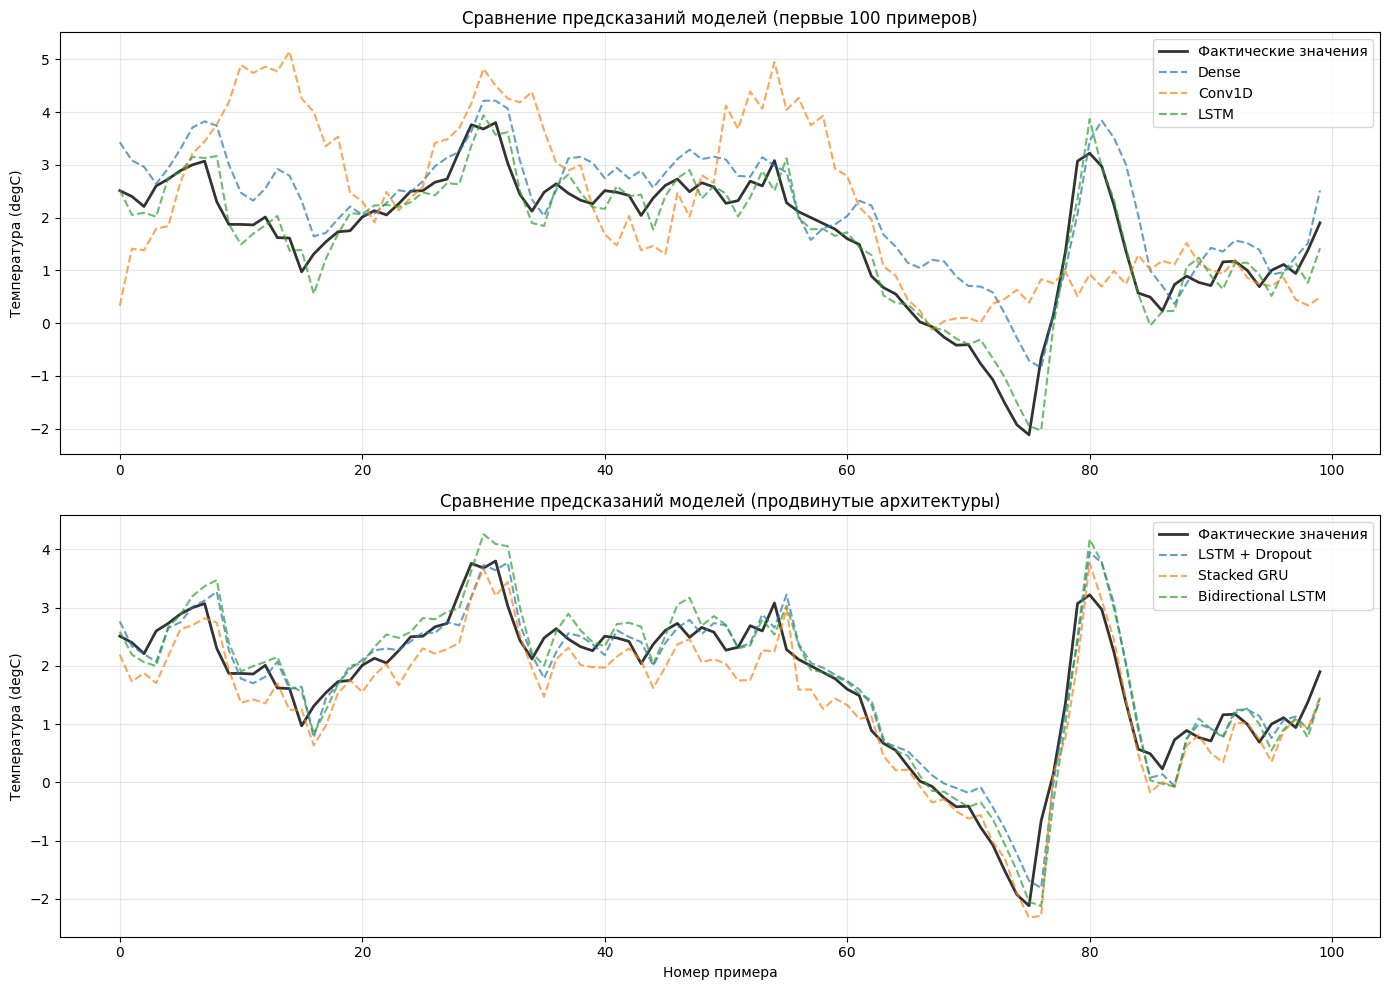

In [128]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

axes[0].plot(targets_dense, label='Фактические значения', color='black', linewidth=2, alpha=0.8)
axes[0].plot(preds_dense, label='Dense', linestyle='--', alpha=0.7)
axes[0].plot(preds_conv, label='Conv1D', linestyle='--', alpha=0.7)
axes[0].plot(preds_lstm, label='LSTM', linestyle='--', alpha=0.7)
axes[0].set_title('Сравнение предсказаний моделей (первые 100 примеров)')
axes[0].set_ylabel('Температура (degC)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(targets_lstm_dropout, label='Фактические значения', color='black', linewidth=2, alpha=0.8)
axes[1].plot(preds_lstm_dropout, label='LSTM + Dropout', linestyle='--', alpha=0.7)
axes[1].plot(preds_stacked_gru, label='Stacked GRU', linestyle='--', alpha=0.7)
axes[1].plot(preds_bilstm, label='Bidirectional LSTM', linestyle='--', alpha=0.7)
axes[1].set_title('Сравнение предсказаний моделей (продвинутые архитектуры)')
axes[1].set_xlabel('Номер примера')
axes[1].set_ylabel('Температура (degC)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

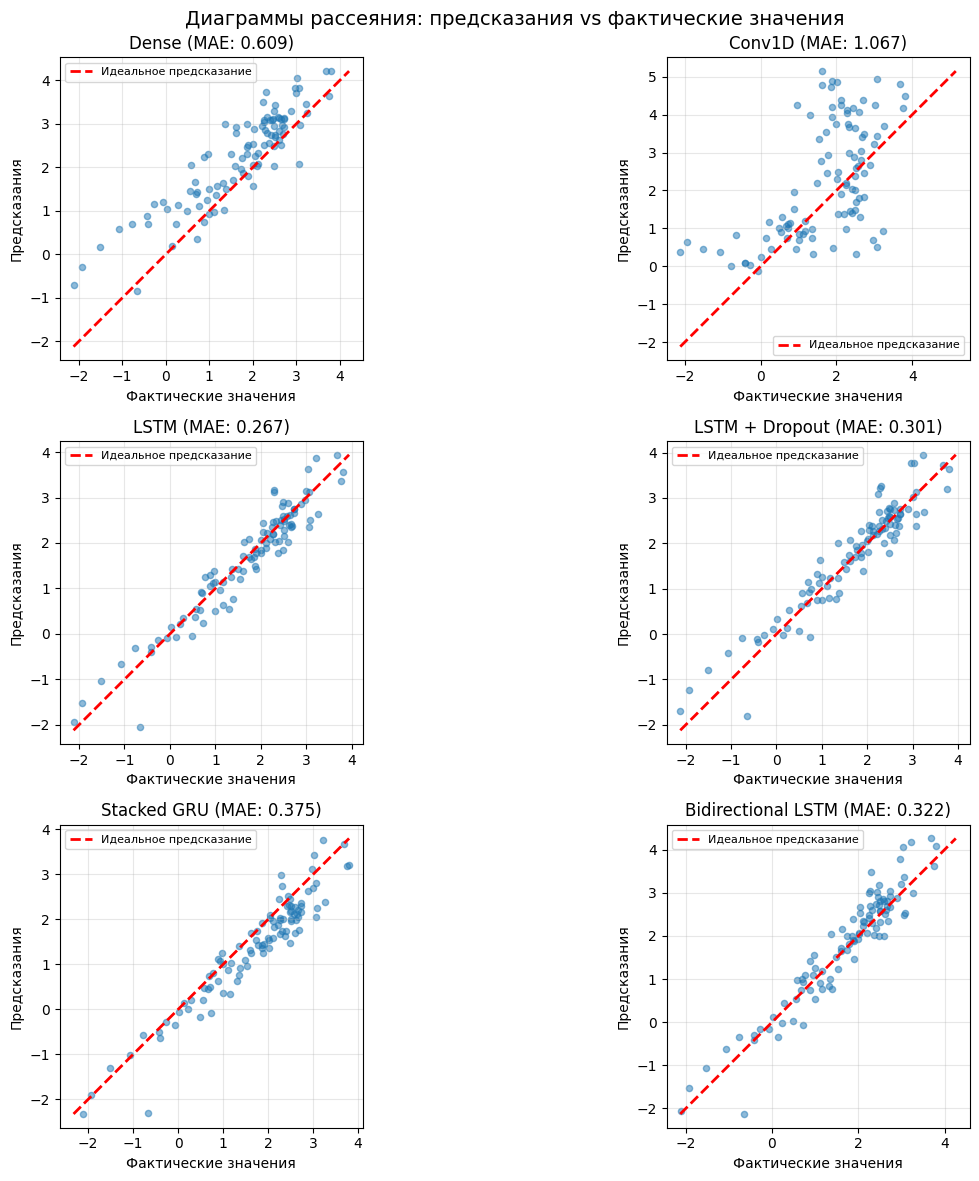

In [129]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

models_data = [
    ('Dense', preds_dense, targets_dense),
    ('Conv1D', preds_conv, targets_conv),
    ('LSTM', preds_lstm, targets_lstm),
    ('LSTM + Dropout', preds_lstm_dropout, targets_lstm_dropout),
    ('Stacked GRU', preds_stacked_gru, targets_stacked_gru),
    ('Bidirectional LSTM', preds_bilstm, targets_bilstm)
]

for ax, (name, preds, targets) in zip(axes.flat, models_data):
    ax.scatter(targets, preds, alpha=0.5, s=20)
    
    min_val = min(targets.min(), preds.min())
    max_val = max(targets.max(), preds.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Идеальное предсказание')
    
    mae = np.mean(np.abs(preds - targets))
    ax.set_title(f'{name} (MAE: {mae:.3f})')
    ax.set_xlabel('Фактические значения')
    ax.set_ylabel('Предсказания')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal')

plt.suptitle('Диаграммы рассеяния: предсказания vs фактические значения', fontsize=14)
plt.tight_layout()
plt.show()

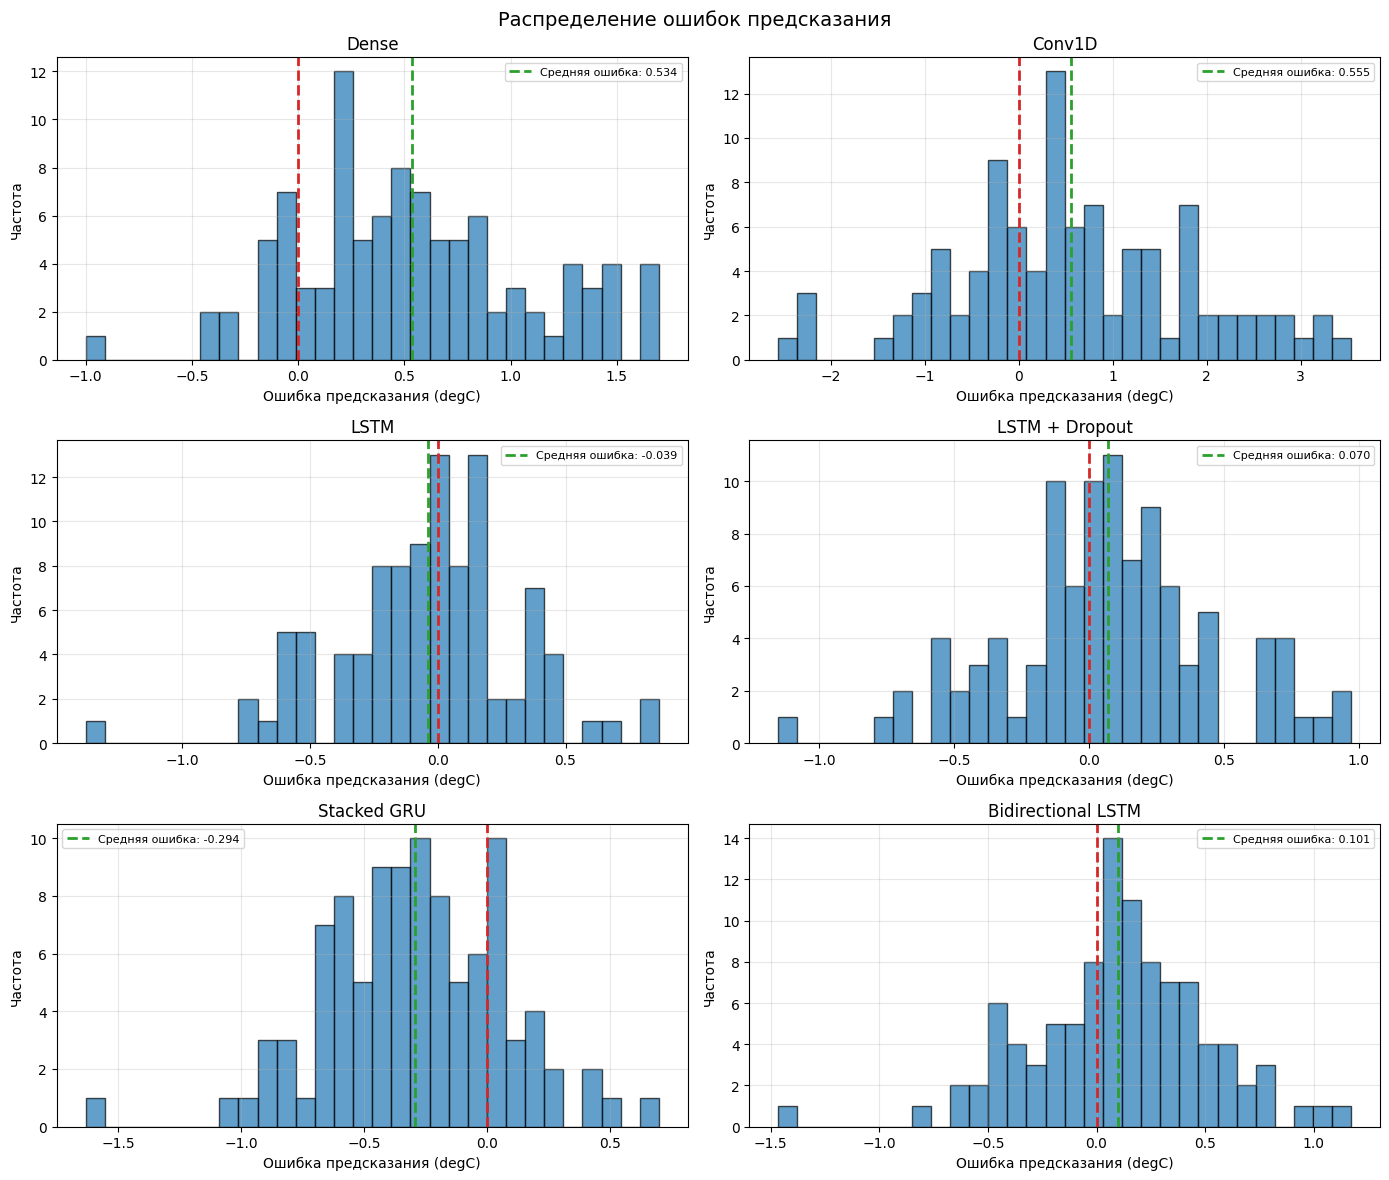

In [130]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, (name, preds, targets) in zip(axes.flat, models_data):
    errors = preds - targets
    ax.hist(errors, bins=30, color='tab:blue', alpha=0.7, edgecolor='black')
    ax.axvline(x=0, color='tab:red', linestyle='--', linewidth=2)
    ax.axvline(x=np.mean(errors), color='tab:green', linestyle='--', linewidth=2, 
               label=f'Средняя ошибка: {np.mean(errors):.3f}')
    ax.set_title(f'{name}')
    ax.set_xlabel('Ошибка предсказания (degC)')
    ax.set_ylabel('Частота')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Распределение ошибок предсказания', fontsize=14)
plt.tight_layout()
plt.show()

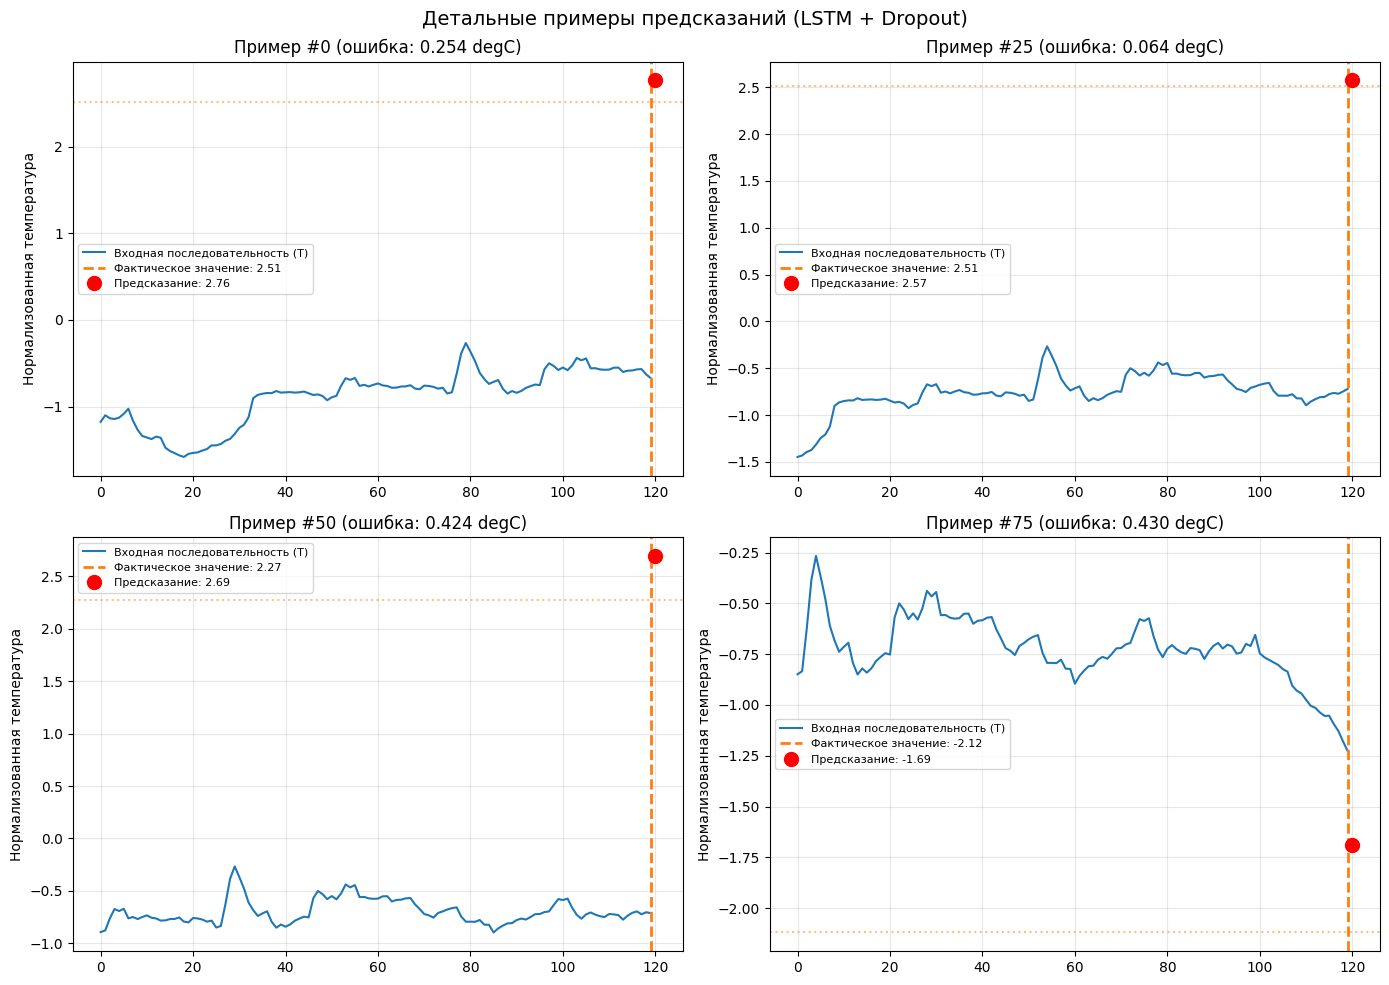

In [131]:
sample_indices = [0, 25, 50, 75]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, idx in zip(axes.flat, sample_indices):
    sample_x, sample_y = test_dataset[idx]
    sample_x = sample_x.numpy()
    
    ax.plot(sample_x[:, 1], color='tab:blue', linewidth=1.5, label='Входная последовательность (T)')
    
    best_pred = preds_lstm_dropout[idx]
    best_target = targets_lstm_dropout[idx]
    
    ax.axvline(x=len(sample_x) - 1, color='tab:orange', linestyle='--', linewidth=2, 
               label=f'Фактическое значение: {best_target:.2f}')
    ax.axhline(y=best_target, color='tab:orange', linestyle=':', alpha=0.5)
    
    ax.plot(len(sample_x), best_pred, 'ro', markersize=10, 
            label=f'Предсказание: {best_pred:.2f}')
    
    error = abs(best_pred - best_target)
    ax.set_title(f'Пример #{idx} (ошибка: {error:.3f} degC)')
    ax.set_ylabel('Нормализованная температура')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Детальные примеры предсказаний (LSTM + Dropout)', fontsize=14)
plt.tight_layout()
plt.show()

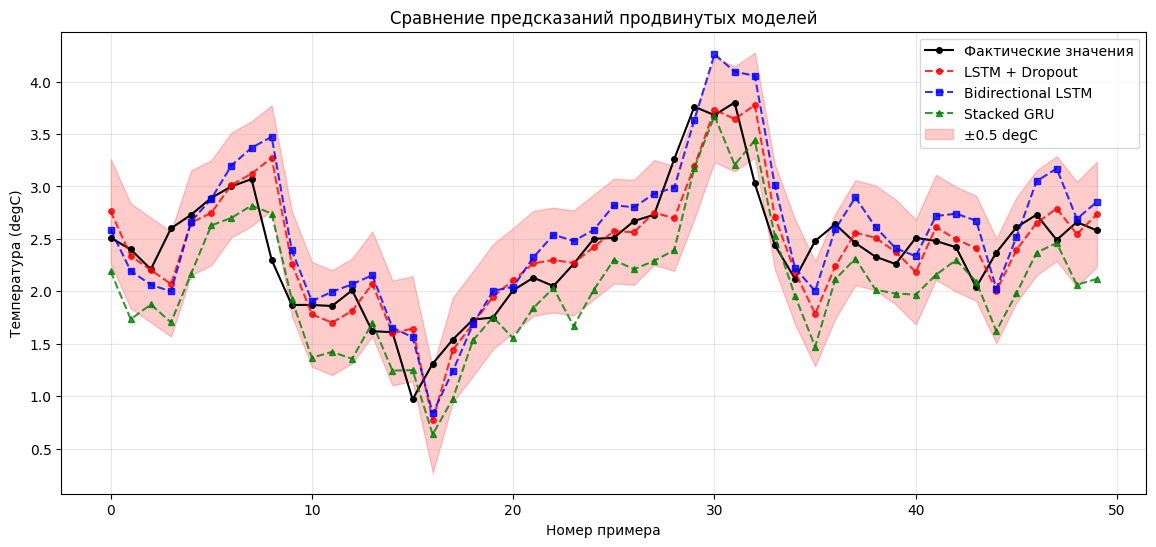

In [132]:
plt.figure(figsize=(14, 6))

window = 50
start_idx = 0

plt.plot(range(window), targets_lstm_dropout[start_idx:start_idx+window], 
         'ko-', label='Фактические значения', markersize=4, linewidth=1.5)
plt.plot(range(window), preds_lstm_dropout[start_idx:start_idx+window], 
         'r--o', label='LSTM + Dropout', markersize=4, linewidth=1.5, alpha=0.8)
plt.plot(range(window), preds_bilstm[start_idx:start_idx+window], 
         'b--s', label='Bidirectional LSTM', markersize=4, linewidth=1.5, alpha=0.8)
plt.plot(range(window), preds_stacked_gru[start_idx:start_idx+window], 
         'g--^', label='Stacked GRU', markersize=4, linewidth=1.5, alpha=0.8)

plt.fill_between(range(window), 
                 preds_lstm_dropout[start_idx:start_idx+window] - 0.5,
                 preds_lstm_dropout[start_idx:start_idx+window] + 0.5,
                 alpha=0.2, color='red', label='±0.5 degC')

plt.title('Сравнение предсказаний продвинутых моделей')
plt.xlabel('Номер примера')
plt.ylabel('Температура (degC)')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

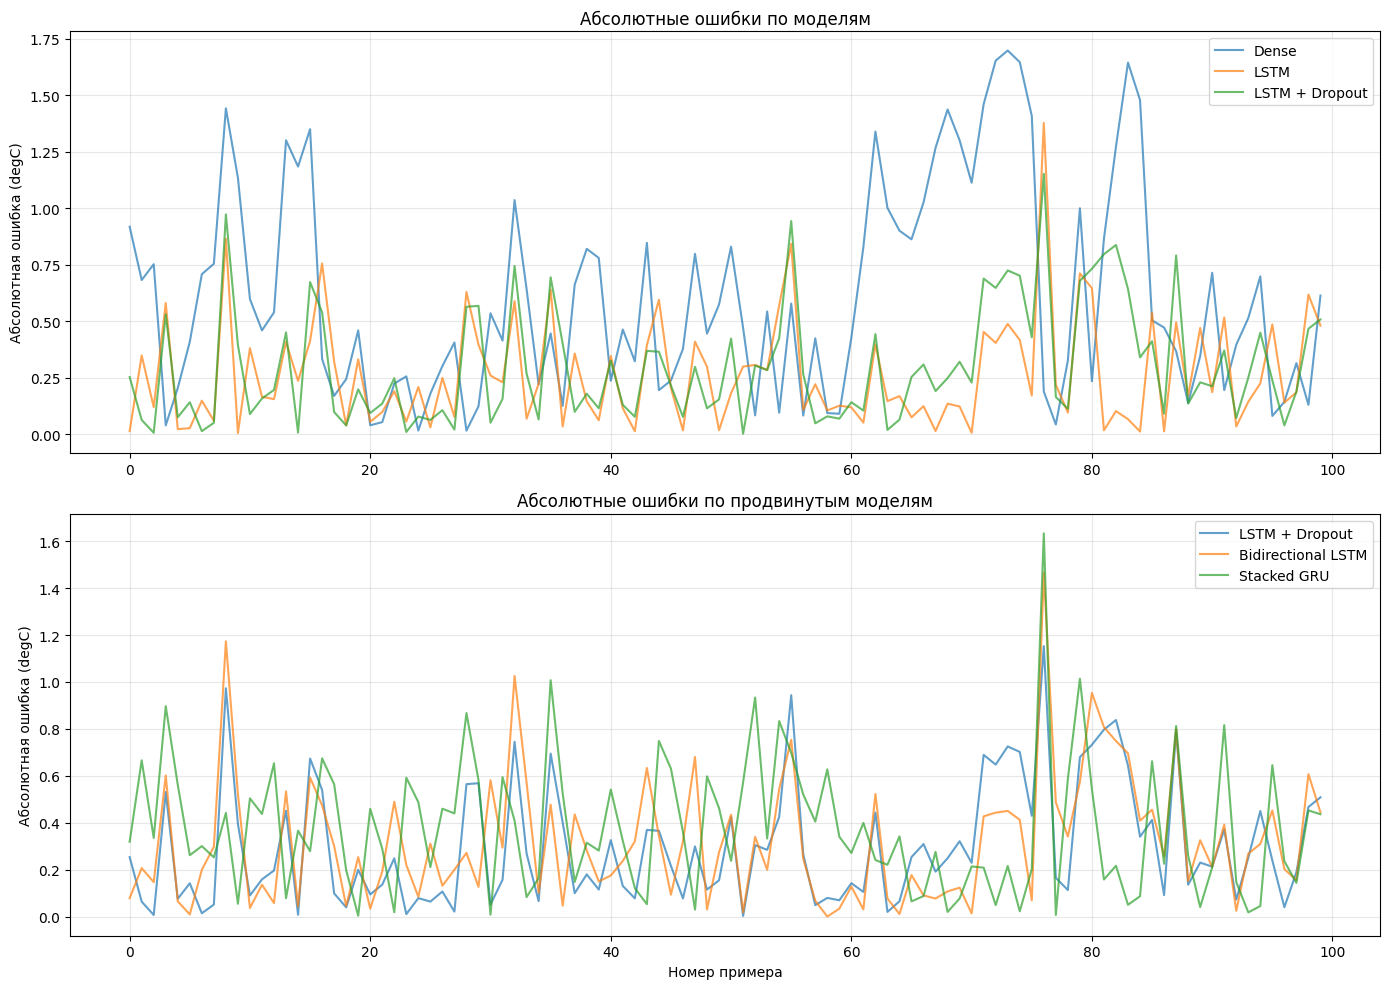

In [133]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

errors_dense = np.abs(preds_dense - targets_dense)
errors_lstm = np.abs(preds_lstm - targets_lstm)
errors_lstm_dropout = np.abs(preds_lstm_dropout - targets_lstm_dropout)

axes[0].plot(errors_dense, label='Dense', alpha=0.7)
axes[0].plot(errors_lstm, label='LSTM', alpha=0.7)
axes[0].plot(errors_lstm_dropout, label='LSTM + Dropout', alpha=0.7)
axes[0].set_title('Абсолютные ошибки по моделям')
axes[0].set_ylabel('Абсолютная ошибка (degC)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

errors_bilstm = np.abs(preds_bilstm - targets_bilstm)
errors_stacked_gru = np.abs(preds_stacked_gru - targets_stacked_gru)

axes[1].plot(errors_lstm_dropout, label='LSTM + Dropout', alpha=0.7)
axes[1].plot(errors_bilstm, label='Bidirectional LSTM', alpha=0.7)
axes[1].plot(errors_stacked_gru, label='Stacked GRU', alpha=0.7)
axes[1].set_title('Абсолютные ошибки по продвинутым моделям')
axes[1].set_xlabel('Номер примера')
axes[1].set_ylabel('Абсолютная ошибка (degC)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [134]:
print("=" * 60)
print("Сравнение моделей")
print("=" * 60)
print(f"{'Модель':<25} {'MAE (degC)':<15} {'RMSE (degC)':<15}")
print("-" * 60)

models_results = [
    ('Dense', preds_dense, targets_dense),
    ('Conv1D', preds_conv, targets_conv),
    ('LSTM', preds_lstm, targets_lstm),
    ('LSTM + Dropout', preds_lstm_dropout, targets_lstm_dropout),
    ('Stacked GRU', preds_stacked_gru, targets_stacked_gru),
    ('Bidirectional LSTM', preds_bilstm, targets_bilstm)
]

best_mae = float('inf')
best_model_name = ''

for name, preds, targets in models_results:
    mae = np.mean(np.abs(preds - targets))
    rmse = np.sqrt(np.mean((preds - targets)**2))
    print(f"{name:<25} {mae:<15.3f} {rmse:<15.3f}")
    if mae < best_mae:
        best_mae = mae
        best_model_name = name

print("-" * 60)
print(f"\nЛучшая модель: {best_model_name} (MAE: {best_mae:.3f} degC)")

Сравнение моделей
Модель                    MAE (degC)      RMSE (degC)    
------------------------------------------------------------
Dense                     0.609           0.761          
Conv1D                    1.067           1.381          
LSTM                      0.267           0.359          
LSTM + Dropout            0.301           0.395          
Stacked GRU               0.375           0.470          
Bidirectional LSTM        0.322           0.422          
------------------------------------------------------------

Лучшая модель: LSTM (MAE: 0.267 degC)


## Заключение

В данном ноутбуке мы рассмотрели несколько архитектур нейронных сетей для прогнозирования температуры:

1. **Полносвязная сеть (Dense)** - базовая модель, преобразует последовательность в вектор
2. **Одномерная сверточная сеть (Conv1D)** - использует локальные паттерны в данных
3. **LSTM** - рекуррентная сеть для обработки временных рядов
4. **LSTM + Dropout** - LSTM с регуляризацией для борьбы с переобучением
5. **Stacked GRU** - несколько слоев GRU для извлечения более сложных признаков
6. **Bidirectional LSTM** - двунаправленная LSTM для учета контекста в обоих направлениях

### Ключевые выводы:
- Рекуррентные модели (LSTM, GRU) обычно показывают лучшие результаты для временных рядов
- Добавление Dropout помогает снизить переобучение
- Двунаправленные модели могут улучшить качество за счет учета будущего контекста
- Важно правильно нормализовать данные и подобрать гиперпараметры

### Возможные улучшения:
- Использование Transformer архитектур
- Ансамблирование моделей
- Подбор гиперпараметров с Optuna или Ray Tune
- Добавление дополнительных признаков (время суток, день недели и т.д.)

### Сравнение с эталоном (baseline)

В качестве простейшего эталонного решения использовался **наивный метод**: прогноз = последнее значение температуры в входной последовательности («температура не изменится»).

Ниже приведено сводное сравнение качества моделей на тестовой выборке (одношаговый прогноз) и при авторегрессивном прогнозе на 24 часа вперёд.